<a href="https://colab.research.google.com/github/rahulsingani/MSc-Dec-2026-Rahul-Singani/blob/main/Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PART 1 — DATA PREPARATION

In [1]:
# DATASET LOADING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("E-COMMERCE RECOMMENDATION SYSTEM")
print("DATASET LOADING")

# ------------------------------------------------------------
# Dataset path
# ------------------------------------------------------------

file_path = "E-Commerce DataSet.xlsx"

# ------------------------------------------------------------
# Check whether the file exists
# ------------------------------------------------------------

if not Path(file_path).exists():
    raise FileNotFoundError(
        f"Dataset file not found: {file_path}"
    )

# ------------------------------------------------------------
# Load Excel dataset
# ------------------------------------------------------------

df = pd.read_excel(file_path)

# Preserve original dataset
raw_df = df.copy()

# ------------------------------------------------------------
# Basic dataset information
# ------------------------------------------------------------

print("\nDataset loaded successfully.")

print("\nDataset Shape:")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst Five Records:")
display(df.head())

print("\nDataset Data Types:")
display(df.dtypes)

print("\nDataset Memory Usage:")
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"{memory_mb:.2f} MB")

print("\nDataset Loading Completed.")

E-COMMERCE RECOMMENDATION SYSTEM
DATASET LOADING

Dataset loaded successfully.

Dataset Shape:
Rows    : 100,000
Columns : 6

Column Names:
['rec_id', 'order_id', 'order_date', 'shipped_at', 'prod_sku', 'prod_qty']

First Five Records:


,rec_id,order_id,order_date,shipped_at,prod_sku,prod_qty
0,3476212,FC__3__296__RS__657__1216__1308861465,2015-11-03 06:44:36,2015-11-05 02:56:08,ACCD6KQ3PRMMPJPT,1
1,3476204,FC__3__296__RS__616__1139__1308857858,2015-11-03 06:43:06,2015-11-03 15:28:51,IT-PB11K,1
2,3472447,FC__3__296__RS__664__1238__58147367,2015-10-31 18:30:00,2015-11-04 10:16:31,1786602,1
3,3634024,FC__3__2__RS__2__1__3006075214,2015-12-01 18:30:00,NaT,ROON_24533_02nd_Dec,1
4,3535415,FC__3__296__RS__652__1200__1325959053,2015-11-11 09:41:33,2015-11-12 14:44:55,Eve HL51 Yellow,1



Dataset Data Types:


,0
rec_id,int64
order_id,object
order_date,datetime64[ns]
shipped_at,datetime64[ns]
prod_sku,object
prod_qty,int64



Dataset Memory Usage:
16.87 MB

Dataset Loading Completed.


In [2]:
# DATA INSPECTION

print(" DATA INSPECTION")

# ------------------------------------------------------------
# Dataset information
# ------------------------------------------------------------

print("\nDataset Information:")
df.info()

# ------------------------------------------------------------
# Descriptive statistics
# ------------------------------------------------------------

print("\nNumerical Summary:")
display(df.describe(include="all").T)

# ------------------------------------------------------------
# Missing values
# ------------------------------------------------------------

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

print("\nMissing Value Summary:")
display(missing_summary)

# ------------------------------------------------------------
# Duplicate records
# ------------------------------------------------------------

duplicate_count = df.duplicated().sum()

print(
    f"\nDuplicate Records: {duplicate_count:,}"
)

# ------------------------------------------------------------
# Unique values
# ------------------------------------------------------------

unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [
        df[column].nunique(dropna=True)
        for column in df.columns
    ]
})

print("\nUnique Value Summary:")
display(unique_summary)

# ------------------------------------------------------------
# Invalid product quantities
# ------------------------------------------------------------

if "prod_qty" in df.columns:

    invalid_quantity_count = (
        pd.to_numeric(
            df["prod_qty"],
            errors="coerce"
        ) <= 0
    ).sum()

    print(
        "\nNon-positive Product Quantities:",
        int(invalid_quantity_count)
    )

# ------------------------------------------------------------
# Date conversion check
# ------------------------------------------------------------

for column in ["order_date", "shipped_at"]:

    if column in df.columns:

        converted_dates = pd.to_datetime(
            df[column],
            errors="coerce"
        )

        invalid_dates = converted_dates.isna().sum()

        print(
            f"\nInvalid {column} values:",
            int(invalid_dates)
        )

# ------------------------------------------------------------
# Order-level statistics
# ------------------------------------------------------------

if "order_id" in df.columns:

    print(
        "\nUnique Orders:",
        f"{df['order_id'].nunique():,}"
    )

if "prod_sku" in df.columns:

    print(
        "Unique Products:",
        f"{df['prod_sku'].nunique():,}"
    )

# ------------------------------------------------------------
# Dataset quality report
# ------------------------------------------------------------

inspection_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Duplicate Records",
        "Unique Orders",
        "Unique Products",
        "Total Missing Values"
    ],
    "Value": [
        len(df),
        len(df.columns),
        duplicate_count,
        df["order_id"].nunique()
            if "order_id" in df.columns else np.nan,
        df["prod_sku"].nunique()
            if "prod_sku" in df.columns else np.nan,
        int(df.isnull().sum().sum())
    ]
})

print("\nOverall Inspection Report:")
display(inspection_report)

print("\nData Inspection Completed.")

 DATA INSPECTION

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   rec_id      100000 non-null  int64         
 1   order_id    100000 non-null  object        
 2   order_date  100000 non-null  datetime64[ns]
 3   shipped_at  88090 non-null   datetime64[ns]
 4   prod_sku    99987 non-null   object        
 5   prod_qty    100000 non-null  int64         
dtypes: datetime64[ns](2), int64(2), object(2)
memory usage: 4.6+ MB

Numerical Summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
rec_id,100000.0,NaN,NaN,NaN,3520014.49885,3099867.0,3485311.75,3547906.5,3594183.25,3635779.0,107517.661081
order_id,100000,85193,FC__3__2__RS__69__61__54560846,340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,100000,NaN,NaN,NaN,2015-11-09 04:34:30.368420096,2011-10-22 08:01:00,2015-11-03 08:57:27.249999872,2015-11-13 07:32:30,2015-11-22 18:30:00,2026-11-15 07:41:00,NaN
shipped_at,88090,NaN,NaN,NaN,2015-11-11 06:25:23.637143808,2015-09-01 06:22:35,2015-11-05 02:56:08,2015-11-15 06:48:19,2015-11-24 11:02:51,2015-12-03 09:27:12,NaN
prod_sku,99987,15442,ROON_24465_06th Oct_TV_2nd_Duplicate,5778,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prod_qty,100000.0,NaN,NaN,NaN,1.41942,0.0,1.0,1.0,1.0,1800.0,9.248329



Missing Value Summary:


,Missing_Count,Missing_Percentage
shipped_at,11910,11.91
prod_sku,13,0.01
order_id,0,0.00
rec_id,0,0.00
order_date,0,0.00
prod_qty,0,0.00



Duplicate Records: 0

Unique Value Summary:


,Column,Unique_Values
0,rec_id,100000
1,order_id,85193
2,order_date,27486
3,shipped_at,5329
4,prod_sku,15442
5,prod_qty,88



Non-positive Product Quantities: 14

Invalid order_date values: 0

Invalid shipped_at values: 11910

Unique Orders: 85,193
Unique Products: 15,442

Overall Inspection Report:


,Metric,Value
0,Total Records,100000
1,Total Columns,6
2,Duplicate Records,0
3,Unique Orders,85193
4,Unique Products,15442
5,Total Missing Values,11923



Data Inspection Completed.


In [3]:
# DATA CLEANING

print("DATA CLEANING")

# ------------------------------------------------------------
# Create independent cleaned dataset
# ------------------------------------------------------------

cleaned_df = df.copy()

# ------------------------------------------------------------
# Standardise column names
# ------------------------------------------------------------

cleaned_df.columns = (
    cleaned_df.columns
    .str.strip()
    .str.lower()
)

print("\nStandardised Columns:")
print(cleaned_df.columns.tolist())

# ------------------------------------------------------------
# Remove completely duplicated records
# ------------------------------------------------------------

before_duplicates = len(cleaned_df)

cleaned_df = cleaned_df.drop_duplicates().copy()

after_duplicates = len(cleaned_df)

print(
    f"\nDuplicate Records Removed: "
    f"{before_duplicates - after_duplicates:,}"
)

# ------------------------------------------------------------
# Clean text columns
# ------------------------------------------------------------

text_columns = [
    "rec_id",
    "order_id",
    "prod_sku"
]

for column in text_columns:

    if column in cleaned_df.columns:

        cleaned_df[column] = (
            cleaned_df[column]
            .astype("string")
            .str.strip()
        )

# ------------------------------------------------------------
# Convert product quantity to numeric
# ------------------------------------------------------------

cleaned_df["prod_qty"] = pd.to_numeric(
    cleaned_df["prod_qty"],
    errors="coerce"
)

# ------------------------------------------------------------
# Convert date columns
# ------------------------------------------------------------

cleaned_df["order_date"] = pd.to_datetime(
    cleaned_df["order_date"],
    errors="coerce"
)

cleaned_df["shipped_at"] = pd.to_datetime(
    cleaned_df["shipped_at"],
    errors="coerce"
)

# ------------------------------------------------------------
# Remove records without essential identifiers
# ------------------------------------------------------------

essential_columns = [
    "order_id",
    "prod_sku",
    "prod_qty",
    "order_date"
]

before_essential = len(cleaned_df)

cleaned_df = cleaned_df.dropna(
    subset=essential_columns
).copy()

print(
    "Records removed due to missing essential fields:",
    before_essential - len(cleaned_df)
)

# ------------------------------------------------------------
# Remove invalid product quantities
# ------------------------------------------------------------

before_quantity = len(cleaned_df)

cleaned_df = cleaned_df[
    cleaned_df["prod_qty"] > 0
].copy()

print(
    "Records removed due to invalid quantities:",
    before_quantity - len(cleaned_df)
)

# ------------------------------------------------------------
# Convert quantity to integer
# ------------------------------------------------------------

cleaned_df["prod_qty"] = (
    cleaned_df["prod_qty"]
    .round()
    .astype("int32")
)

# ------------------------------------------------------------
# Handle missing shipping dates
# ------------------------------------------------------------
# Missing shipping dates are retained as missing because
# artificial shipping dates should not be introduced.

print(
    "\nMissing shipping dates retained:",
    int(cleaned_df["shipped_at"].isna().sum())
)

# ------------------------------------------------------------
# 1Remove impossible shipping dates
# ------------------------------------------------------------

invalid_shipping = (
    cleaned_df["shipped_at"].notna()
    &
    (
        cleaned_df["shipped_at"]
        < cleaned_df["order_date"]
    )
)

print(
    "Invalid shipping-before-order records:",
    int(invalid_shipping.sum())
)

cleaned_df.loc[
    invalid_shipping,
    "shipped_at"
] = pd.NaT

# ------------------------------------------------------------
# Final cleaning validation
# ------------------------------------------------------------

print("\nCleaned Dataset Shape:")
print(cleaned_df.shape)

print("\nRemaining Missing Values:")
display(
    cleaned_df.isnull().sum()
)

print("\nRemaining Duplicates:")
print(cleaned_df.duplicated().sum())

print("\nCleaned Dataset Preview:")
display(cleaned_df.head())

print("\nData Cleaning Completed.")

DATA CLEANING

Standardised Columns:
['rec_id', 'order_id', 'order_date', 'shipped_at', 'prod_sku', 'prod_qty']

Duplicate Records Removed: 0
Records removed due to missing essential fields: 13
Records removed due to invalid quantities: 1

Missing shipping dates retained: 11909
Invalid shipping-before-order records: 38

Cleaned Dataset Shape:
(99986, 6)

Remaining Missing Values:


,0
rec_id,0
order_id,0
order_date,0
shipped_at,11947
prod_sku,0
prod_qty,0



Remaining Duplicates:
0

Cleaned Dataset Preview:


,rec_id,order_id,order_date,shipped_at,prod_sku,prod_qty
0,3476212,FC__3__296__RS__657__1216__1308861465,2015-11-03 06:44:36,2015-11-05 02:56:08,ACCD6KQ3PRMMPJPT,1
1,3476204,FC__3__296__RS__616__1139__1308857858,2015-11-03 06:43:06,2015-11-03 15:28:51,IT-PB11K,1
2,3472447,FC__3__296__RS__664__1238__58147367,2015-10-31 18:30:00,2015-11-04 10:16:31,1786602,1
3,3634024,FC__3__2__RS__2__1__3006075214,2015-12-01 18:30:00,NaT,ROON_24533_02nd_Dec,1
4,3535415,FC__3__296__RS__652__1200__1325959053,2015-11-11 09:41:33,2015-11-12 14:44:55,Eve HL51 Yellow,1



Data Cleaning Completed.


In [4]:
# FEATURE ENGINEERING

print("FEATURE ENGINEERING")

# ------------------------------------------------------------
# Work from cleaned dataset
# ------------------------------------------------------------

model_df = cleaned_df.copy()

# ------------------------------------------------------------
# Order date features
# ------------------------------------------------------------

model_df["order_year"] = (
    model_df["order_date"].dt.year
)

model_df["order_month"] = (
    model_df["order_date"].dt.month
)

model_df["order_month_name"] = (
    model_df["order_date"].dt.month_name()
)

model_df["order_day"] = (
    model_df["order_date"].dt.day
)

model_df["order_day_of_week"] = (
    model_df["order_date"].dt.dayofweek
)

model_df["order_day_name"] = (
    model_df["order_date"].dt.day_name()
)

model_df["order_hour"] = (
    model_df["order_date"].dt.hour
)

# ------------------------------------------------------------
# Weekend indicator
# ------------------------------------------------------------

model_df["is_weekend"] = (
    model_df["order_day_of_week"] >= 5
).astype("int8")

# ------------------------------------------------------------
# Shipping delay
# ------------------------------------------------------------

model_df["shipping_delay_hours"] = (
    model_df["shipped_at"]
    - model_df["order_date"]
).dt.total_seconds() / 3600

model_df["shipping_delay_days"] = (
    model_df["shipping_delay_hours"] / 24
)

# ------------------------------------------------------------
# Shipping status
# ------------------------------------------------------------

model_df["shipping_status"] = np.where(
    model_df["shipped_at"].isna(),
    "Not Shipped",
    "Shipped"
)

# ------------------------------------------------------------
# Order-level line count
# ------------------------------------------------------------

order_line_count = (
    model_df
    .groupby("order_id")["prod_sku"]
    .nunique()
    .rename("order_line_count")
)

model_df = model_df.merge(
    order_line_count,
    on="order_id",
    how="left"
)

# ------------------------------------------------------------
# Order classification
# ------------------------------------------------------------

model_df["order_type"] = np.where(
    model_df["order_line_count"] == 1,
    "Single-Line",
    "Multi-Line"
)

# ------------------------------------------------------------
# 7uantity per order
# ------------------------------------------------------------

order_total_quantity = (
    model_df
    .groupby("order_id")["prod_qty"]
    .sum()
    .rename("order_total_quantity")
)

model_df = model_df.merge(
    order_total_quantity,
    on="order_id",
    how="left"
)

# ------------------------------------------------------------
# Product popularity
# ------------------------------------------------------------

product_order_frequency = (
    model_df
    .groupby("prod_sku")["order_id"]
    .nunique()
    .rename("product_order_frequency")
)

model_df = model_df.merge(
    product_order_frequency,
    on="prod_sku",
    how="left"
)

# ------------------------------------------------------------
# Final feature check
# ------------------------------------------------------------

print("\nFeature-Engineered Dataset Shape:")
print(model_df.shape)

print("\nNew Features:")
new_features = [
    "order_year",
    "order_month",
    "order_day",
    "order_day_of_week",
    "order_hour",
    "is_weekend",
    "shipping_delay_hours",
    "shipping_delay_days",
    "shipping_status",
    "order_line_count",
    "order_type",
    "order_total_quantity",
    "product_order_frequency"
]

display(
    model_df[new_features].head()
)

print("\nFeature Data Types:")
display(
    model_df[new_features].dtypes
)

print("\nFeature Engineering Completed.")

FEATURE ENGINEERING

Feature-Engineered Dataset Shape:
(99986, 21)

New Features:


,order_year,order_month,order_day,order_day_of_week,order_hour,is_weekend,shipping_delay_hours,shipping_delay_days,shipping_status,order_line_count,order_type,order_total_quantity,product_order_frequency
0,2015,11,3,1,6,0,44.192222,1.841343,Shipped,1,Single-Line,2,256
1,2015,11,3,1,6,0,8.762500,0.365104,Shipped,1,Single-Line,2,2377
2,2015,10,31,5,18,1,87.775278,3.657303,Shipped,1,Single-Line,1,1636
3,2015,12,1,1,18,0,NaN,NaN,Not Shipped,1,Single-Line,1,110
4,2015,11,11,2,9,0,29.056111,1.210671,Shipped,1,Single-Line,1,52



Feature Data Types:


,0
order_year,int32
order_month,int32
order_day,int32
order_day_of_week,int32
order_hour,int32
is_weekend,int8
shipping_delay_hours,float64
shipping_delay_days,float64
shipping_status,object
order_line_count,int64



Feature Engineering Completed.


EXPLORATORY DATA ANALYSIS

KEY DATASET INDICATORS


,Metric,Value
0,Total Records,99986
1,Unique Orders,85188
2,Unique Products,15436
3,Total Quantity,141942
4,Single-Line Orders,82924
5,Multi-Line Orders,2264



Top 10 Products by Number of Orders


,prod_sku,Order_Count
0,ROON_24465_06th Oct_TV_2nd_Duplicate,5772
1,ROON_24478_30th Oct_TV_AD_4th_Duplicate,3636
2,ROON_24494_13th_Nov_TV_AD,3386
3,ROON_244322_14Aug,2906
4,ROON_244345_21Aug_TV_AD,2836
5,IT-PB11K,2377
6,1786602,1636
7,ROON_244371_7 Sep,1552
8,1786612,1311
9,1786606,1059


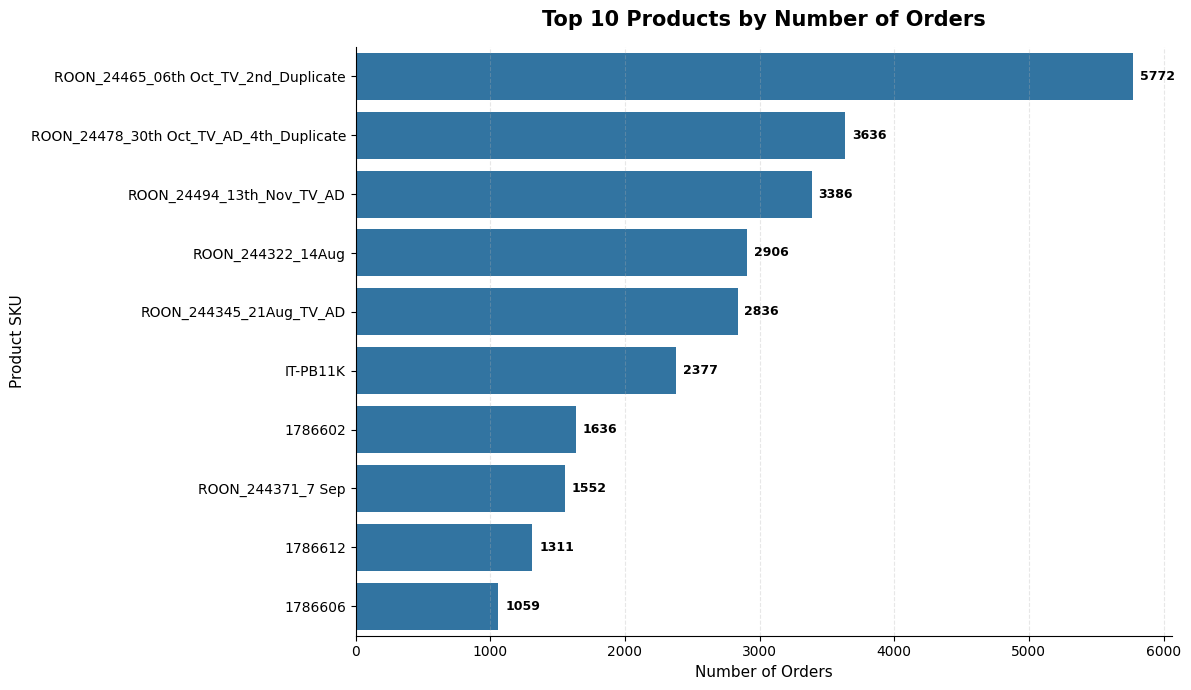


Top 10 Products by Total Quantity


,prod_sku,Total_Quantity
0,ROON_24465_06th Oct_TV_2nd_Duplicate,5778
1,ROON_24478_30th Oct_TV_AD_4th_Duplicate,3638
2,ROON_24494_13th_Nov_TV_AD,3386
3,ROON_244322_14Aug,2906
4,ROON_244345_21Aug_TV_AD,2837
5,IT-PB11K,2514
6,16034,2280
7,13015,2016
8,1786602,1636
9,ROON_244371_7 Sep,1556


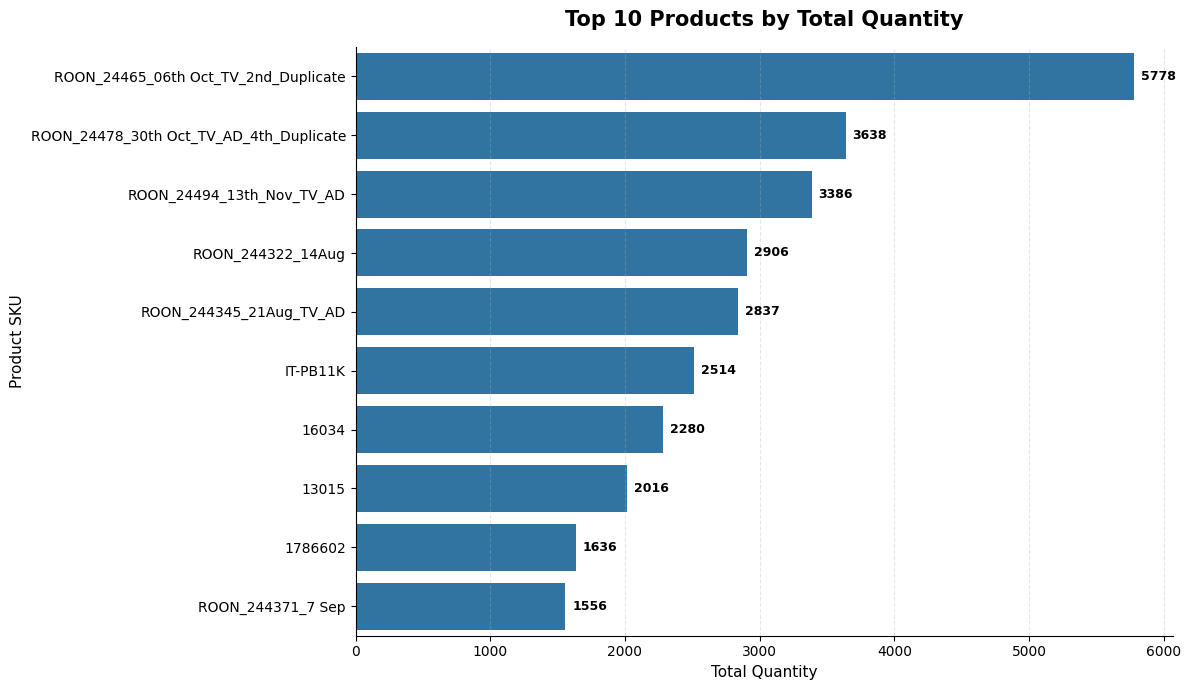


Single-Line vs Multi-Line Orders


,order_type,Order_Count
0,Multi-Line,2264
1,Single-Line,82924


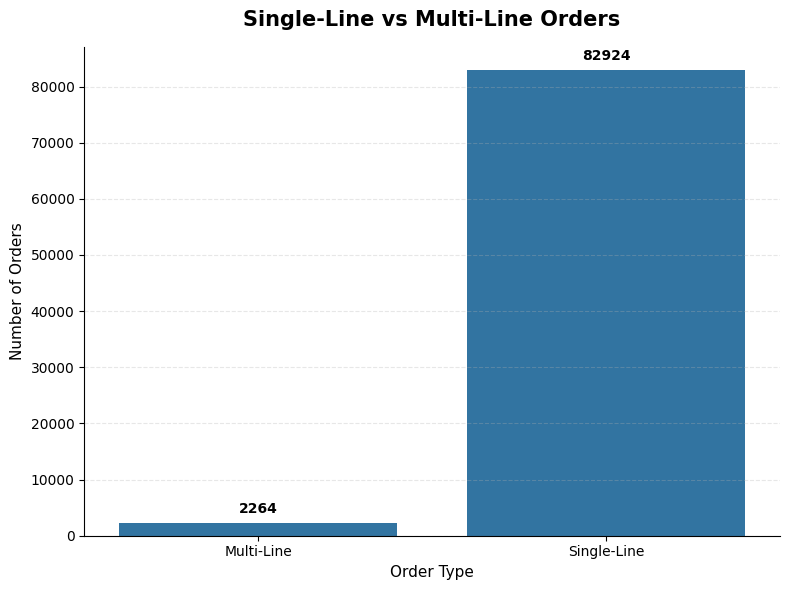


Monthly Order Distribution


,order_year,order_month,Order_Count,Period
0,2011,10,16,2011-10
1,2011,11,58,2011-11
2,2011,12,2,2011-12
3,2012,10,3,2012-10
4,2013,10,3,2013-10
5,2014,11,1,2014-11
6,2015,2,1,2015-02
7,2015,4,49,2015-04
8,2015,5,3,2015-05
9,2015,7,9,2015-07


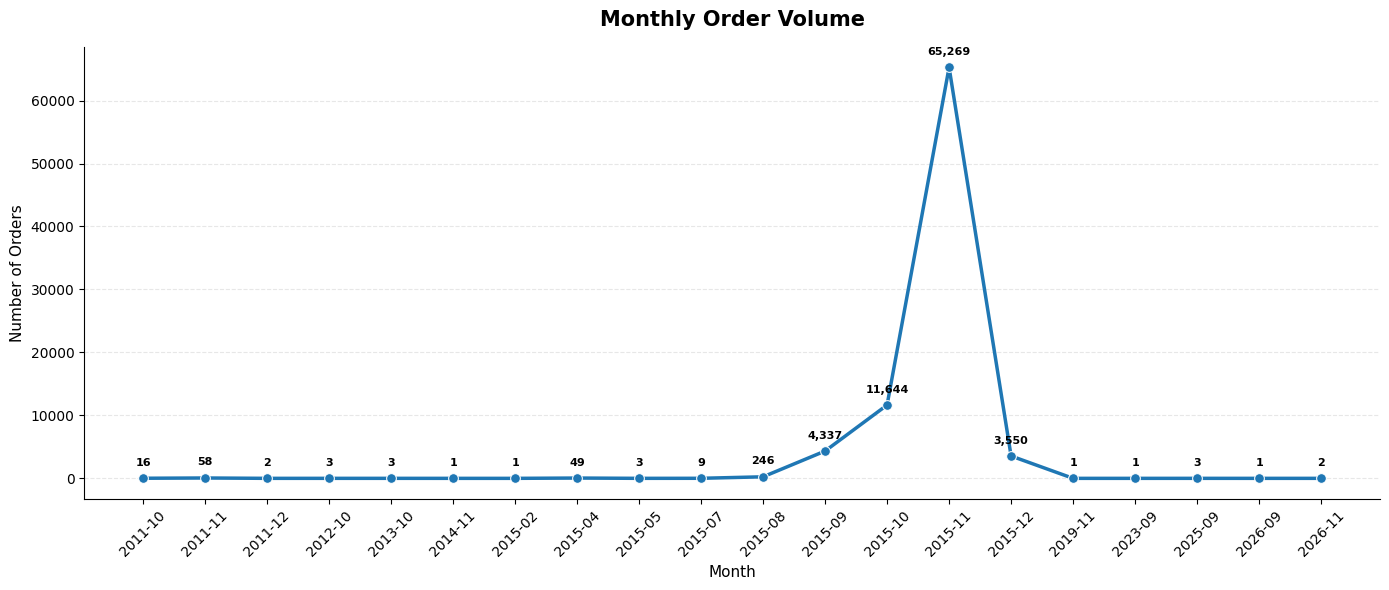


Orders by Day of Week


,Day,Order_Count
0,Monday,12385
1,Tuesday,16806
2,Wednesday,14392
3,Thursday,12896
4,Friday,10473
5,Saturday,8732
6,Sunday,9583


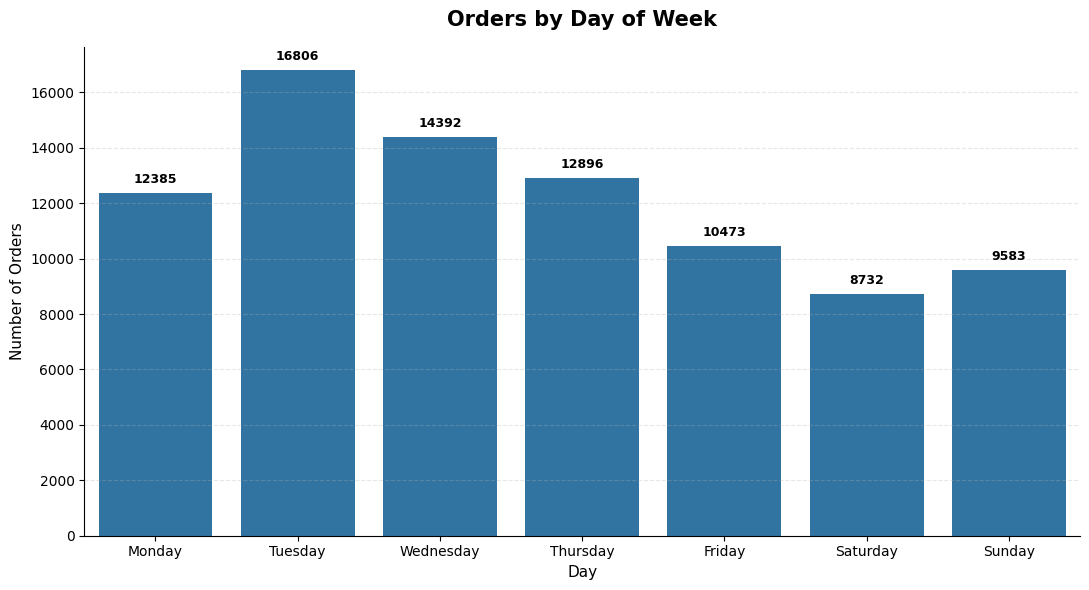


Orders by Hour


,order_hour,Order_Count
0,0,136
1,1,243
2,2,709
3,3,935
4,4,1381
5,5,2271
6,6,2590
7,7,3222
8,8,2501
9,9,2301


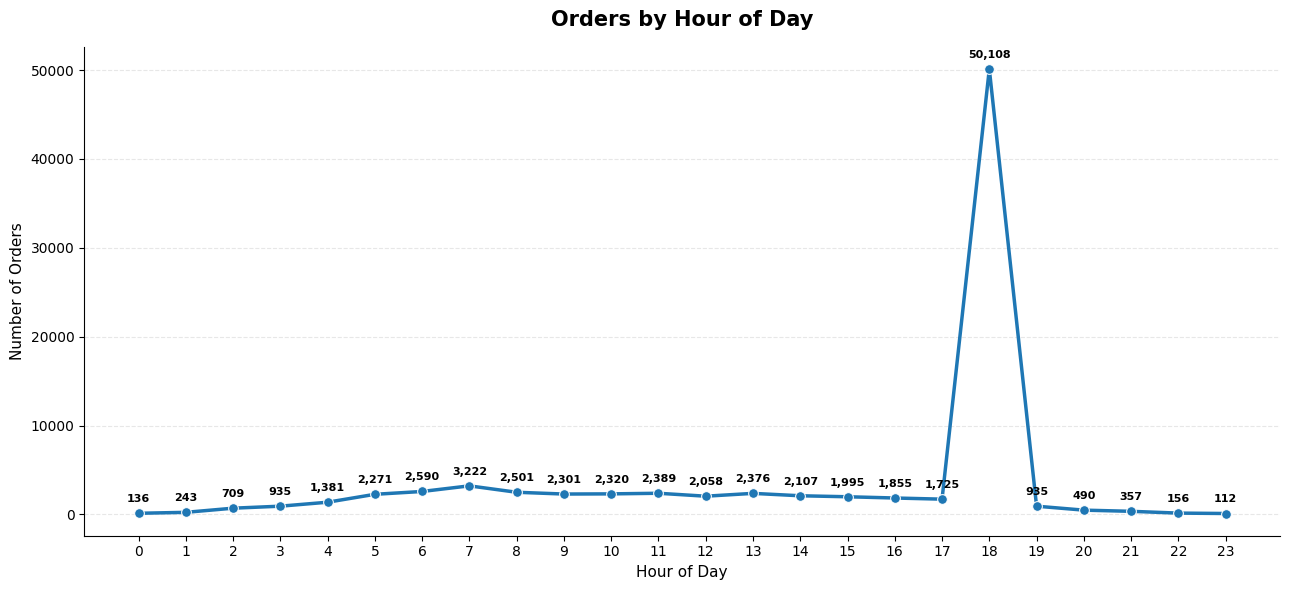

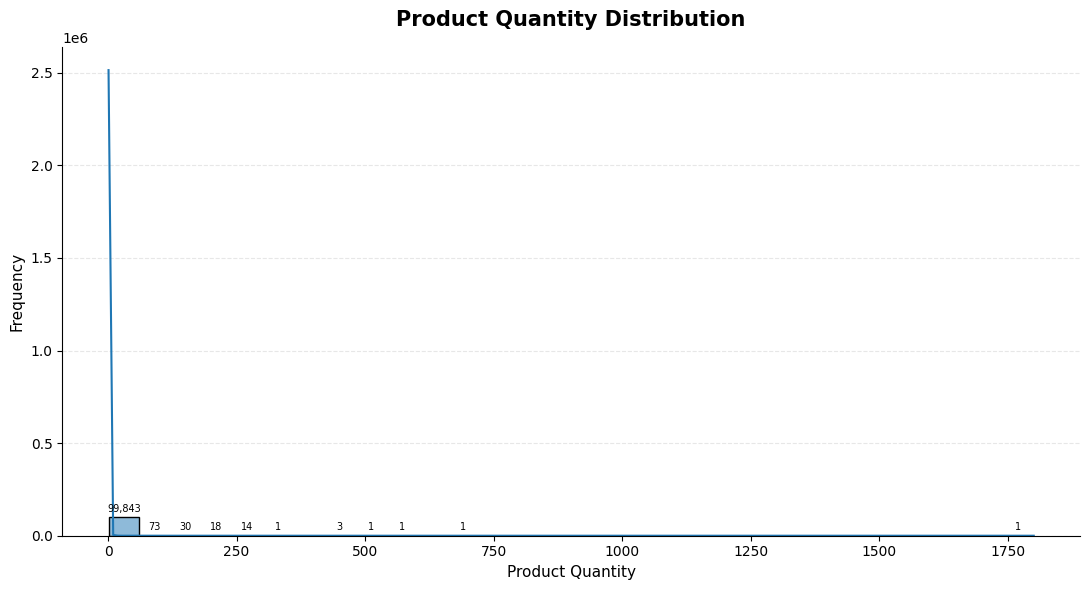


Records with Valid Shipping Delay: 88039

Shipping Delay Statistics


,shipping_delay_days
count,88039.000000
mean,4.424395
std,44.287592
min,0.010567
25%,0.981238
50%,1.656829
75%,3.524502
max,1466.102870


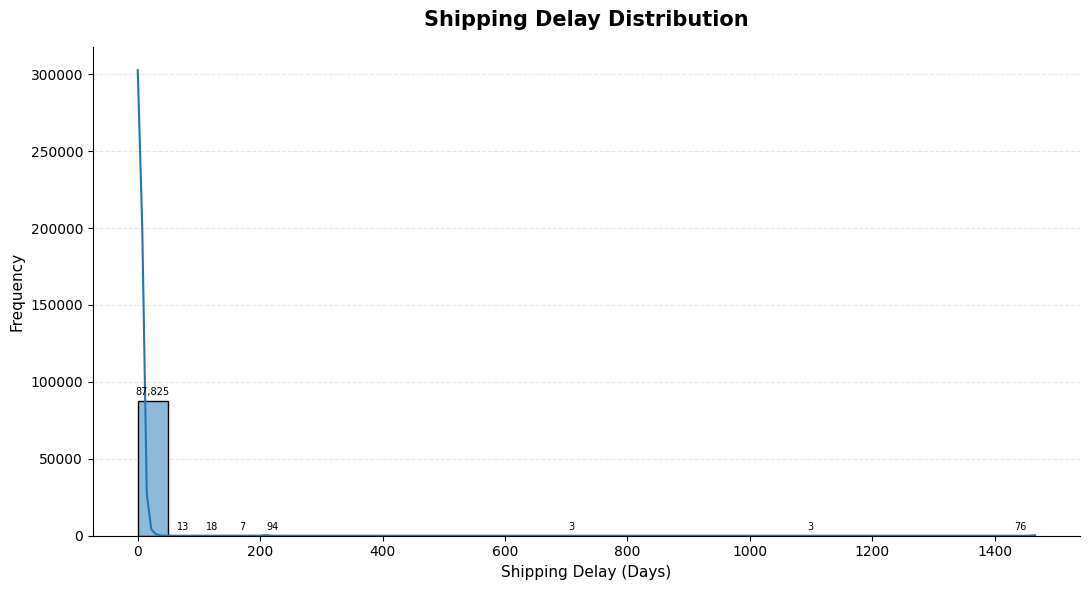


EDA SUMMARY
Total records              : 99,986
Unique orders              : 85,188
Unique products            : 15,436
Single-line orders         : 82,924
Multi-line orders          : 2,264
Total product quantity     : 141,942

Exploratory Data Analysis Completed.


In [5]:
# EXPLORATORY DATA ANALYSIS

print("EXPLORATORY DATA ANALYSIS")

# ------------------------------------------------------------
# Basic KPIs
# ------------------------------------------------------------

total_records = len(model_df)
unique_orders = model_df["order_id"].nunique()
unique_products = model_df["prod_sku"].nunique()
total_quantity = model_df["prod_qty"].sum()

single_line_orders = (
    model_df.loc[
        model_df["order_type"] == "Single-Line",
        "order_id"
    ].nunique()
)

multi_line_orders = (
    model_df.loc[
        model_df["order_type"] == "Multi-Line",
        "order_id"
    ].nunique()
)

print("\nKEY DATASET INDICATORS")

kpi_table = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Unique Orders",
        "Unique Products",
        "Total Quantity",
        "Single-Line Orders",
        "Multi-Line Orders"
    ],
    "Value": [
        total_records,
        unique_orders,
        unique_products,
        total_quantity,
        single_line_orders,
        multi_line_orders
    ]
})

display(kpi_table)


# ============================================================
# TOP PRODUCTS BY ORDER FREQUENCY
# ============================================================

top_products = (
    model_df
    .groupby("prod_sku")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Order_Count")
)

print("\nTop 10 Products by Number of Orders")
display(top_products)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_products,
    x="Order_Count",
    y="prod_sku"
)

plt.title(
    "Top 10 Products by Number of Orders",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Number of Orders",
    fontsize=11
)

plt.ylabel(
    "Product SKU",
    fontsize=11
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%d",
        padding=5,
        fontsize=9,
        fontweight="bold"
    )

sns.despine()

plt.tight_layout()
plt.show()


# ============================================================
# TOP PRODUCTS BY QUANTITY
# ============================================================

top_quantity_products = (
    model_df
    .groupby("prod_sku")["prod_qty"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Total_Quantity")
)

print("\nTop 10 Products by Total Quantity")
display(top_quantity_products)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_quantity_products,
    x="Total_Quantity",
    y="prod_sku"
)

plt.title(
    "Top 10 Products by Total Quantity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Total Quantity",
    fontsize=11
)

plt.ylabel(
    "Product SKU",
    fontsize=11
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%d",
        padding=5,
        fontsize=9,
        fontweight="bold"
    )

sns.despine()

plt.tight_layout()
plt.show()


# ============================================================
# ORDER TYPE DISTRIBUTION
# ============================================================

order_type_data = (
    model_df
    .groupby("order_type")["order_id"]
    .nunique()
    .reset_index(name="Order_Count")
)

print("\nSingle-Line vs Multi-Line Orders")
display(order_type_data)

plt.figure(figsize=(8, 6))

ax = sns.barplot(
    data=order_type_data,
    x="order_type",
    y="Order_Count"
)

plt.title(
    "Single-Line vs Multi-Line Orders",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Order Type",
    fontsize=11
)

plt.ylabel(
    "Number of Orders",
    fontsize=11
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%d",
        padding=5,
        fontsize=10,
        fontweight="bold"
    )

sns.despine()

plt.tight_layout()
plt.show()


# ============================================================
# ORDERS BY MONTH
# ============================================================

monthly_orders = (
    model_df
    .groupby(
        ["order_year", "order_month"]
    )["order_id"]
    .nunique()
    .reset_index(name="Order_Count")
)

monthly_orders["Period"] = (
    monthly_orders["order_year"].astype(str)
    + "-"
    + monthly_orders["order_month"]
    .astype(str)
    .str.zfill(2)
)

print("\nMonthly Order Distribution")
display(monthly_orders)

plt.figure(figsize=(14, 6))

ax = sns.lineplot(
    data=monthly_orders,
    x="Period",
    y="Order_Count",
    marker="o",
    linewidth=2.5,
    markersize=7
)

plt.title(
    "Monthly Order Volume",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Month",
    fontsize=11
)

plt.ylabel(
    "Number of Orders",
    fontsize=11
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Add values to each point
for x, y in zip(
    monthly_orders["Period"],
    monthly_orders["Order_Count"]
):

    ax.annotate(
        f"{y:,}",
        (x, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold"
    )

plt.xticks(rotation=45)

sns.despine()

plt.tight_layout()
plt.show()


# ============================================================
# ORDERS BY DAY OF WEEK
# ============================================================

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_orders = (
    model_df
    .groupby("order_day_name")["order_id"]
    .nunique()
    .reindex(day_order)
    .reset_index()
)

weekday_orders.columns = [
    "Day",
    "Order_Count"
]

print("\nOrders by Day of Week")
display(weekday_orders)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=weekday_orders,
    x="Day",
    y="Order_Count"
)

plt.title(
    "Orders by Day of Week",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Day",
    fontsize=11
)

plt.ylabel(
    "Number of Orders",
    fontsize=11
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%d",
        padding=5,
        fontsize=9,
        fontweight="bold"
    )

sns.despine()

plt.tight_layout()
plt.show()


# ============================================================
# ORDERS BY HOUR
# ============================================================

hourly_orders = (
    model_df
    .groupby("order_hour")["order_id"]
    .nunique()
    .reset_index(name="Order_Count")
)

print("\nOrders by Hour")
display(hourly_orders)

plt.figure(figsize=(13, 6))

ax = sns.lineplot(
    data=hourly_orders,
    x="order_hour",
    y="Order_Count",
    marker="o",
    linewidth=2.5,
    markersize=7
)

plt.title(
    "Orders by Hour of Day",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Hour of Day",
    fontsize=11
)

plt.ylabel(
    "Number of Orders",
    fontsize=11
)

plt.xticks(
    range(0, 24)
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Add values to each point
for x, y in zip(
    hourly_orders["order_hour"],
    hourly_orders["Order_Count"]
):

    ax.annotate(
        f"{y:,}",
        (x, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold"
    )

sns.despine()

plt.tight_layout()
plt.show()


# ============================================================
# PRODUCT QUANTITY DISTRIBUTION
# ============================================================

plt.figure(figsize=(11, 6))

ax = sns.histplot(
    model_df["prod_qty"],
    bins=30,
    kde=True
)

plt.title(
    "Product Quantity Distribution",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Product Quantity",
    fontsize=11
)

plt.ylabel(
    "Frequency",
    fontsize=11
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Add frequency labels
for patch in ax.patches:

    height = patch.get_height()

    if height > 0:

        ax.annotate(
            f"{int(height):,}",
            (
                patch.get_x()
                + patch.get_width() / 2,
                height
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=7
        )

sns.despine()

plt.tight_layout()
plt.show()


# ============================================================
# SHIPPING DELAY DISTRIBUTION
# ============================================================

shipping_data = model_df[
    model_df["shipping_delay_days"].notna()
    &
    (model_df["shipping_delay_days"] >= 0)
]

print(
    "\nRecords with Valid Shipping Delay:",
    len(shipping_data)
)

if len(shipping_data) > 0:

    print("\nShipping Delay Statistics")

    display(
        shipping_data[
            "shipping_delay_days"
        ].describe()
    )

    plt.figure(figsize=(11, 6))

    ax = sns.histplot(
        shipping_data["shipping_delay_days"],
        bins=30,
        kde=True
    )

    plt.title(
        "Shipping Delay Distribution",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    plt.xlabel(
        "Shipping Delay (Days)",
        fontsize=11
    )

    plt.ylabel(
        "Frequency",
        fontsize=11
    )

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    for patch in ax.patches:

        height = patch.get_height()

        if height > 0:

            ax.annotate(
                f"{int(height):,}",
                (
                    patch.get_x()
                    + patch.get_width() / 2,
                    height
                ),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                fontsize=7
            )

    sns.despine()

    plt.tight_layout()
    plt.show()


# ============================================================
# FINAL EDA SUMMARY
# ============================================================

print("\nEDA SUMMARY")

print(
    f"Total records              : {total_records:,}"
)

print(
    f"Unique orders              : {unique_orders:,}"
)

print(
    f"Unique products            : {unique_products:,}"
)

print(
    f"Single-line orders         : {single_line_orders:,}"
)

print(
    f"Multi-line orders          : {multi_line_orders:,}"
)

print(
    f"Total product quantity     : {total_quantity:,}"
)

print(
    "\nExploratory Data Analysis Completed."
)

## PART 2 — INTERACTION DATA

In [ ]:
# ORDER-PRODUCT INTERACTION MATRIX

print("INTERACTION DATA")
print("ORDER-PRODUCT INTERACTION MATRIX")

# ------------------------------------------------------------
# Create order-product interaction matrix
# ------------------------------------------------------------
# Rows    = Orders
# Columns = Product SKUs
# Values  = Product quantity

interaction_matrix = pd.pivot_table(
    model_df,
    index="order_id",
    columns="prod_sku",
    values="prod_qty",
    aggfunc="sum",
    fill_value=0
)

# ------------------------------------------------------------
# Ensure numeric representation
# ------------------------------------------------------------

interaction_matrix = interaction_matrix.astype(
    "int32"
)

# ------------------------------------------------------------
# Matrix information
# ------------------------------------------------------------

print("\nInteraction Matrix Shape:")
print(
    f"Rows (Orders)    : {interaction_matrix.shape[0]:,}"
)

print(
    f"Columns (SKUs)   : {interaction_matrix.shape[1]:,}"
)

print(
    f"Matrix Elements  : "
    f"{interaction_matrix.shape[0] * interaction_matrix.shape[1]:,}"
)

# ------------------------------------------------------------
# Display sample
# ------------------------------------------------------------

print("\nSample of Order-Product Interaction Matrix:")

display(
    interaction_matrix.iloc[:10, :10]
)

# ------------------------------------------------------------
# Interaction statistics
# ------------------------------------------------------------

non_zero_interactions = (
    interaction_matrix > 0
).sum().sum()

total_matrix_elements = (
    interaction_matrix.shape[0]
    * interaction_matrix.shape[1]
)

matrix_density = (
    non_zero_interactions
    / total_matrix_elements
) * 100

print("\nInteraction Statistics")

print(
    f"Non-zero interactions : "
    f"{non_zero_interactions:,}"
)

print(
    f"Zero interactions     : "
    f"{total_matrix_elements - non_zero_interactions:,}"
)

print(
    f"Matrix density        : "
    f"{matrix_density:.4f}%"
)

print(
    f"Matrix sparsity       : "
    f"{100 - matrix_density:.4f}%"
)

print("\nOrder-Product Interaction Matrix Created.")

INTERACTION DATA
ORDER-PRODUCT INTERACTION MATRIX


In [ ]:
# BINARY INTERACTION MATRIX

print("BINARY INTERACTION MATRIX")

# ------------------------------------------------------------
# Convert quantity interactions into purchase interactions
# ------------------------------------------------------------
# 1 = Product is present in the order
# 0 = Product is not present in the order

binary_interaction_matrix = (
    interaction_matrix > 0
).astype("int8")

# ------------------------------------------------------------
# Matrix information
# ------------------------------------------------------------

print("\nBinary Interaction Matrix Shape:")

print(
    f"Rows (Orders)  : "
    f"{binary_interaction_matrix.shape[0]:,}"
)

print(
    f"Columns (SKUs) : "
    f"{binary_interaction_matrix.shape[1]:,}"
)

# ------------------------------------------------------------
# Display sample
# ------------------------------------------------------------

print("\nSample Binary Interaction Matrix:")

display(
    binary_interaction_matrix.iloc[:10, :10]
)

# ------------------------------------------------------------
# Calculate interaction counts
# ------------------------------------------------------------

binary_interactions = (
    binary_interaction_matrix.sum().sum()
)

print(
    "\nTotal Positive Interactions:",
    f"{binary_interactions:,}"
)

# ------------------------------------------------------------
# Products per order
# ------------------------------------------------------------

products_per_order = (
    binary_interaction_matrix.sum(axis=1)
)

print("\nProducts per Order Statistics:")

display(
    products_per_order.describe()
)

# ------------------------------------------------------------
# Orders by number of products
# ------------------------------------------------------------

order_product_distribution = (
    products_per_order
    .value_counts()
    .sort_index()
    .reset_index()
)

order_product_distribution.columns = [
    "Number_of_Products",
    "Number_of_Orders"
]

print("\nDistribution of Products per Order:")

display(
    order_product_distribution.head(15)
)

# ------------------------------------------------------------
# Single-line and multi-line orders
# ------------------------------------------------------------

single_line_count = (
    products_per_order == 1
).sum()

multi_line_count = (
    products_per_order > 1
).sum()

print(
    "\nSingle-Line Orders:",
    f"{single_line_count:,}"
)

print(
    "Multi-Line Orders:",
    f"{multi_line_count:,}"
)

# ------------------------------------------------------------
# Binary matrix density
# ------------------------------------------------------------

total_elements = (
    binary_interaction_matrix.shape[0]
    * binary_interaction_matrix.shape[1]
)

binary_density = (
    binary_interactions
    / total_elements
) * 100

print(
    "\nBinary Matrix Density:",
    f"{binary_density:.4f}%"
)

print(
    "Binary Matrix Sparsity:",
    f"{100 - binary_density:.4f}%"
)

print("\nBinary Interaction Matrix Created.")

In [ ]:
# SPARSE INTERACTION MATRIX

print("SPARSE INTERACTION MATRIX")

from scipy.sparse import csr_matrix

# ------------------------------------------------------------
# Create sparse quantity matrix
# ------------------------------------------------------------

sparse_matrix = csr_matrix(
    interaction_matrix.values
)

# ------------------------------------------------------------
# Create sparse binary matrix
# ------------------------------------------------------------

binary_sparse_matrix = csr_matrix(
    binary_interaction_matrix.values
)

# ------------------------------------------------------------
# Sparse matrix information
# ------------------------------------------------------------

print("\nSparse Quantity Matrix")

print(
    "Shape:",
    sparse_matrix.shape
)

print(
    "Non-zero values:",
    f"{sparse_matrix.nnz:,}"
)

print(
    "Data type:",
    sparse_matrix.dtype
)

# ------------------------------------------------------------
# Binary sparse matrix information
# ------------------------------------------------------------

print("\nSparse Binary Matrix")

print(
    "Shape:",
    binary_sparse_matrix.shape
)

print(
    "Non-zero values:",
    f"{binary_sparse_matrix.nnz:,}"
)

print(
    "Data type:",
    binary_sparse_matrix.dtype
)

# ------------------------------------------------------------
# Memory comparison
# ------------------------------------------------------------

dense_memory_mb = (
    interaction_matrix.memory_usage(
        index=True
    ).sum()
    / (1024 ** 2)
)

sparse_memory_mb = (
    (
        sparse_matrix.data.nbytes
        + sparse_matrix.indices.nbytes
        + sparse_matrix.indptr.nbytes
    )
    / (1024 ** 2)
)

print("\nMemory Comparison")

print(
    f"Dense Matrix Memory  : "
    f"{dense_memory_mb:.2f} MB"
)

print(
    f"Sparse Matrix Memory : "
    f"{sparse_memory_mb:.2f} MB"
)

if sparse_memory_mb > 0:

    print(
        f"Approximate Memory Reduction: "
        f"{(1 - sparse_memory_mb / dense_memory_mb) * 100:.2f}%"
    )

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

dense_from_sparse = sparse_matrix.toarray()

matrix_matches = np.array_equal(
    dense_from_sparse,
    interaction_matrix.values
)

print(
    "\nSparse Matrix Validation:",
    "PASSED" if matrix_matches else "FAILED"
)

binary_dense_from_sparse = (
    binary_sparse_matrix.toarray()
)

binary_matches = np.array_equal(
    binary_dense_from_sparse,
    binary_interaction_matrix.values
)

print(
    "Binary Sparse Matrix Validation:",
    "PASSED" if binary_matches else "FAILED"
)

print("\nSparse Interaction Matrices Created Successfully.")

## PART 3 — USER-BASED CF

In [ ]:
# USER-BASED COLLABORATIVE FILTERING
# SIMILARITY CALCULATION

from sklearn.metrics.pairwise import cosine_similarity

print("USER-BASED COLLABORATIVE FILTERING")
print("SIMILARITY CALCULATION")

# ------------------------------------------------------------
# Count distinct products in each order
# ------------------------------------------------------------

products_per_order = (
    binary_interaction_matrix.sum(axis=1)
)

print("\nProducts per Order:")
display(
    products_per_order.describe()
)

# ------------------------------------------------------------
# Identify multi-product orders
# ------------------------------------------------------------
# Orders containing at least two products provide a more
# useful interaction pattern for similarity calculation.

multi_product_orders = products_per_order[
    products_per_order >= 2
].index

print(
    "\nMulti-Product Orders:",
    f"{len(multi_product_orders):,}"
)

# ------------------------------------------------------------
# Validate availability
# ------------------------------------------------------------

if len(multi_product_orders) == 0:

    raise ValueError(
        "No multi-product orders are available for "
        "User-Based Collaborative Filtering."
    )

# ------------------------------------------------------------
# Select target order
# ------------------------------------------------------------

sample_user = multi_product_orders[0]

print(
    "\nTarget Order:",
    sample_user
)

# ------------------------------------------------------------
# Find target order position
# ------------------------------------------------------------

target_index = (
    binary_interaction_matrix.index
    .get_loc(sample_user)
)

# ------------------------------------------------------------
# Calculate cosine similarity
# ------------------------------------------------------------
# Binary interactions are used:
# 1 = product is present
# 0 = product is absent

user_similarity = cosine_similarity(
    binary_sparse_matrix[target_index],
    binary_sparse_matrix
).flatten()

# ------------------------------------------------------------
# Create similarity table
# ------------------------------------------------------------

user_similarity_df = pd.DataFrame({
    "Order_ID": binary_interaction_matrix.index,
    "Similarity": user_similarity
})

# ------------------------------------------------------------
# Remove target order
# ------------------------------------------------------------

user_similarity_df = user_similarity_df[
    user_similarity_df["Order_ID"] != sample_user
].copy()

# ------------------------------------------------------------
# Keep positive similarity values
# ------------------------------------------------------------

user_similarity_df = user_similarity_df[
    user_similarity_df["Similarity"] > 0
].copy()

print(
    "\nOrders with Positive Similarity:",
    f"{len(user_similarity_df):,}"
)

# ------------------------------------------------------------
# Similarity statistics
# ------------------------------------------------------------

if len(user_similarity_df) > 0:

    print("\nSimilarity Statistics:")

    display(
        user_similarity_df["Similarity"].describe()
    )

else:

    print(
        "\nNo positive similarity is available "
        "for the selected target order."
    )

print("\nSimilarity Calculation Completed.")

In [ ]:
# SIMILAR-ORDER IDENTIFICATION

print("SIMILAR-ORDER IDENTIFICATION")

# ------------------------------------------------------------
# Select top similar orders
# ------------------------------------------------------------

top_similar_orders = (
    user_similarity_df
    .sort_values(
        by="Similarity",
        ascending=False
    )
    .head(20)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Add number of products for each similar order
# ------------------------------------------------------------

if len(top_similar_orders) > 0:

    top_similar_orders["Product_Count"] = (
        top_similar_orders["Order_ID"]
        .map(products_per_order)
    )

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print(
    "\nTop Similar Orders for Target Order:",
    sample_user
)

if len(top_similar_orders) > 0:

    display(top_similar_orders)

else:

    print(
        "No similar orders are available."
    )

# ------------------------------------------------------------
# Plot similarity values
# ------------------------------------------------------------

if len(top_similar_orders) > 0:

    plot_data = top_similar_orders.head(10).copy()

    plt.figure(figsize=(11, 6))

    ax = sns.barplot(
        data=plot_data,
        x="Similarity",
        y="Order_ID"
    )

    plt.title(
        "Top 10 Similar Orders"
    )

    plt.xlabel(
        "Cosine Similarity"
    )

    plt.ylabel(
        "Order ID"
    )

    for i, value in enumerate(
        plot_data["Similarity"]
    ):

        ax.text(
            value + 0.003,
            i,
            f"{value:.3f}",
            va="center",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

print("\nSimilar-Order Identification Completed.")

In [ ]:
# TOP SIMILAR ORDERS

print("TOP SIMILAR ORDERS")

# ------------------------------------------------------------
# Select final Top-10 similar orders
# ------------------------------------------------------------

top_10_similar_orders = (
    user_similarity_df
    .sort_values(
        by="Similarity",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Add interaction information
# ------------------------------------------------------------

if len(top_10_similar_orders) > 0:

    top_10_similar_orders["Product_Count"] = (
        top_10_similar_orders["Order_ID"]
        .map(products_per_order)
    )

# ------------------------------------------------------------
# Display final table
# ------------------------------------------------------------

print(
    "\nTarget Order:",
    sample_user
)

print(
    "Products in Target Order:",
    int(products_per_order.loc[sample_user])
)

print("\nTop 10 Similar Orders:")

if len(top_10_similar_orders) > 0:

    display(
        top_10_similar_orders
    )

    # --------------------------------------------------------
    # Similarity summary
    # --------------------------------------------------------

    print("\nSimilarity Summary")

    print(
        "Highest Similarity:",
        round(
            top_10_similar_orders[
                "Similarity"
            ].max(),
            4
        )
    )

    print(
        "Average Top-10 Similarity:",
        round(
            top_10_similar_orders[
                "Similarity"
            ].mean(),
            4
        )
    )

    print(
        "Lowest Top-10 Similarity:",
        round(
            top_10_similar_orders[
                "Similarity"
            ].min(),
            4
        )
    )

else:

    print(
        "No positive-similarity orders are available."
    )

print("\nTop Similar Orders Analysis Completed.")

In [ ]:
# USER-BASED PRODUCT RECOMMENDATIONS

print("USER-BASED PRODUCT RECOMMENDATIONS")

# ------------------------------------------------------------
# Products already present in target order
# ------------------------------------------------------------

target_products = (
    binary_interaction_matrix
    .loc[sample_user]
)

target_products = target_products[
    target_products > 0
].index.tolist()

print(
    "\nTarget Order:",
    sample_user
)

print(
    "Products Already Present:",
    len(target_products)
)

print(
    "\nTarget Products:"
)

print(target_products)

# ------------------------------------------------------------
# Generate recommendation scores
# ------------------------------------------------------------

recommendation_scores = {}

if len(top_10_similar_orders) > 0:

    for _, row in top_10_similar_orders.iterrows():

        similar_order = row["Order_ID"]

        similarity = row["Similarity"]

        # Products in similar order
        similar_products = (
            binary_interaction_matrix
            .loc[similar_order]
        )

        similar_products = similar_products[
            similar_products > 0
        ].index.tolist()

        # ----------------------------------------------------
        # Add similarity contribution
        # ----------------------------------------------------

        for product in similar_products:

            # Existing products are excluded
            if product not in target_products:

                recommendation_scores[product] = (
                    recommendation_scores.get(
                        product,
                        0
                    ) + similarity
                )

# ------------------------------------------------------------
# Convert scores to DataFrame
# ------------------------------------------------------------

if len(recommendation_scores) > 0:

    user_based_recommendations = pd.DataFrame(
        recommendation_scores.items(),
        columns=[
            "Product_SKU",
            "Recommendation_Score"
        ]
    )

    user_based_recommendations = (
        user_based_recommendations
        .sort_values(
            by="Recommendation_Score",
            ascending=False
        )
        .head(10)
        .reset_index(drop=True)
    )

else:

    user_based_recommendations = pd.DataFrame(
        columns=[
            "Product_SKU",
            "Recommendation_Score"
        ]
    )

# ------------------------------------------------------------
# Display recommendations
# ------------------------------------------------------------

print(
    "\nTop 10 User-Based Product Recommendations"
)

if len(user_based_recommendations) > 0:

    display(
        user_based_recommendations
    )

else:

    print(
        "No recommendation candidates are available."
    )

# ------------------------------------------------------------
# Recommendation plot
# ------------------------------------------------------------

if len(user_based_recommendations) > 0:

    plt.figure(figsize=(11, 6))

    ax = sns.barplot(
        data=user_based_recommendations,
        x="Recommendation_Score",
        y="Product_SKU"
    )

    plt.title(
        "Top 10 User-Based Product Recommendations"
    )

    plt.xlabel(
        "Recommendation Score"
    )

    plt.ylabel(
        "Product SKU"
    )

    for i, value in enumerate(
        user_based_recommendations[
            "Recommendation_Score"
        ]
    ):

        ax.text(
            value + 0.01,
            i,
            f"{value:.3f}",
            va="center",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# Recommendation summary
# ------------------------------------------------------------

print("\nRecommendation Summary")

print(
    "Target Order:",
    sample_user
)

print(
    "Products Already Present:",
    len(target_products)
)

print(
    "Similar Orders Used:",
    len(top_10_similar_orders)
)

print(
    "Recommended Products:",
    len(user_based_recommendations)
)

if len(user_based_recommendations) > 0:

    print(
        "\nHighest Recommendation Score:",
        round(
            user_based_recommendations[
                "Recommendation_Score"
            ].max(),
            4
        )
    )

    print(
        "\nTop Recommended Product:"
    )

    display(
        user_based_recommendations.head(1)
    )

print(
    "\nUser-Based Collaborative Filtering Completed Successfully."
)

In [ ]:
print("USER-BASED COLLABORATIVE FILTERING EVALUATION")

# ------------------------------------------------------------
# Evaluation settings
# ------------------------------------------------------------

K = 10
MAX_EVALUATION_ORDERS = 100
SIMILAR_ORDER_COUNT = 50

# ------------------------------------------------------------
# Identify eligible orders
# ------------------------------------------------------------

products_per_order = (
    binary_interaction_matrix.sum(axis=1)
)

eligible_orders = (
    products_per_order[
        products_per_order >= 2
    ]
    .index
    .tolist()
)

print(
    "\nEligible Orders:",
    f"{len(eligible_orders):,}"
)

# ------------------------------------------------------------
# Select evaluation orders
# ------------------------------------------------------------

evaluation_orders = eligible_orders[
    :MAX_EVALUATION_ORDERS
]

print(
    "Orders Selected for Evaluation:",
    f"{len(evaluation_orders):,}"
)

# ------------------------------------------------------------
# Evaluation containers
# ------------------------------------------------------------

precision_values = []
recall_values = []
f1_values = []

# RMSE containers
rmse_actual_values = []
rmse_predicted_values = []

evaluated_orders = 0
orders_without_candidates = 0

# ------------------------------------------------------------
# Evaluate multiple orders
# ------------------------------------------------------------

for evaluation_order in evaluation_orders:

    # --------------------------------------------------------
    # Products in target order
    # --------------------------------------------------------

    target_products = (
        binary_interaction_matrix
        .loc[evaluation_order]
    )

    target_products = (
        target_products[
            target_products > 0
        ]
        .index
        .tolist()
    )

    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if len(target_products) < 2:
        continue

    # --------------------------------------------------------
    # Hold out one product
    # --------------------------------------------------------

    hidden_product = target_products[-1]

    known_products = target_products[:-1]

    # --------------------------------------------------------
    # Create masked target vector
    # --------------------------------------------------------

    target_vector = (
        binary_interaction_matrix
        .loc[evaluation_order]
        .copy()
    )

    target_vector.loc[hidden_product] = 0

    target_sparse_vector = csr_matrix(
        target_vector.values.reshape(1, -1)
    )

    # --------------------------------------------------------
    # Calculate similarity with other orders
    # --------------------------------------------------------

    similarity_scores = cosine_similarity(
        target_sparse_vector,
        binary_sparse_matrix
    ).flatten()

    similarity_df = pd.DataFrame({

        "Order_ID":
            binary_interaction_matrix.index,

        "Similarity":
            similarity_scores

    })

    # --------------------------------------------------------
    # Remove target order
    # --------------------------------------------------------

    similarity_df = similarity_df[
        similarity_df["Order_ID"]
        != evaluation_order
    ]

    # --------------------------------------------------------
    # Keep positive similarities
    # --------------------------------------------------------

    similarity_df = similarity_df[
        similarity_df["Similarity"] > 0
    ]

    # --------------------------------------------------------
    # Select similar orders
    # --------------------------------------------------------

    similar_orders = (
        similarity_df
        .sort_values(
            by="Similarity",
            ascending=False
        )
        .head(SIMILAR_ORDER_COUNT)
    )

    # --------------------------------------------------------
    # Generate recommendation scores
    # --------------------------------------------------------

    recommendation_scores = {}

    for _, row in similar_orders.iterrows():

        similar_order = row["Order_ID"]

        similarity = row["Similarity"]

        similar_products = (
            binary_interaction_matrix
            .loc[similar_order]
        )

        similar_products = (
            similar_products[
                similar_products > 0
            ]
            .index
            .tolist()
        )

        for product in similar_products:

            # Known products are excluded
            if product not in known_products:

                recommendation_scores[product] = (
                    recommendation_scores.get(
                        product,
                        0
                    )
                    + similarity
                )

    # --------------------------------------------------------
    # Check recommendation candidates
    # --------------------------------------------------------

    if len(recommendation_scores) == 0:

        orders_without_candidates += 1

        continue

    # --------------------------------------------------------
    # Rank recommendations
    # --------------------------------------------------------

    recommendations = (
        pd.DataFrame(
            recommendation_scores.items(),
            columns=[
                "Product_SKU",
                "Recommendation_Score"
            ]
        )
        .sort_values(
            by="Recommendation_Score",
            ascending=False
        )
        .head(K)
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Recommended products
    # --------------------------------------------------------

    recommended_products = set(
        recommendations[
            "Product_SKU"
        ]
    )

    # --------------------------------------------------------
    # Relevant product
    # --------------------------------------------------------

    relevant_products = {
        hidden_product
    }

    # --------------------------------------------------------
    # Calculate hits
    # --------------------------------------------------------

    hits = len(
        recommended_products
        &
        relevant_products
    )

    # --------------------------------------------------------
    # Precision@10
    # --------------------------------------------------------

    precision = (
        hits / K
    )

    # --------------------------------------------------------
    # Recall@10
    # --------------------------------------------------------

    recall = (
        hits /
        len(relevant_products)
    )

    # --------------------------------------------------------
    # F1@10
    # --------------------------------------------------------

    if (
        precision + recall
    ) > 0:

        f1 = (
            2
            * precision
            * recall
            /
            (
                precision
                + recall
            )
        )

    else:

        f1 = 0

    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------
    # Actual relevance:
    # hidden product is relevant = 1
    #
    # Predicted relevance:
    # recommendation score for the hidden product.
    #
    # If the hidden product is not recommended,
    # its predicted score is treated as 0.

    hidden_product_score = (
        recommendation_scores.get(
            hidden_product,
            0
        )
    )

    # --------------------------------------------------------
    # Normalise score for RMSE
    # --------------------------------------------------------
    # Recommendation scores can be greater than 1 because
    # contributions from several similar orders are added.
    #
    # The score is therefore converted to a 0-1 scale.

    max_score = max(
        recommendation_scores.values()
    )

    if max_score > 0:

        predicted_relevance = (
            hidden_product_score /
            max_score
        )

    else:

        predicted_relevance = 0

    # Actual relevance of hidden product
    actual_relevance = 1

    rmse_actual_values.append(
        actual_relevance
    )

    rmse_predicted_values.append(
        predicted_relevance
    )

    # --------------------------------------------------------
    # Store ranking metrics
    # --------------------------------------------------------

    precision_values.append(
        precision
    )

    recall_values.append(
        recall
    )

    f1_values.append(
        f1
    )

    evaluated_orders += 1

# ------------------------------------------------------------
# Calculate final ranking metrics
# ------------------------------------------------------------

if evaluated_orders > 0:

    user_precision_at_10 = np.mean(
        precision_values
    )

    user_recall_at_10 = np.mean(
        recall_values
    )

    user_f1_at_10 = np.mean(
        f1_values
    )

else:

    user_precision_at_10 = 0
    user_recall_at_10 = 0
    user_f1_at_10 = 0

# ------------------------------------------------------------
# Calculate User-Based RMSE
# ------------------------------------------------------------

if len(rmse_actual_values) > 0:

    user_rmse = np.sqrt(
        np.mean(
            (
                np.array(
                    rmse_actual_values
                )
                -
                np.array(
                    rmse_predicted_values
                )
            ) ** 2
        )
    )

else:

    user_rmse = np.nan

# ------------------------------------------------------------
# Display evaluation results
# ------------------------------------------------------------

print(
    "\nUSER-BASED CF EVALUATION RESULTS"
)

print(
    "\nEligible Orders:",
    f"{len(eligible_orders):,}"
)

print(
    "Orders Selected:",
    f"{len(evaluation_orders):,}"
)

print(
    "Orders Successfully Evaluated:",
    f"{evaluated_orders:,}"
)

print(
    "Orders Without Recommendation Candidates:",
    f"{orders_without_candidates:,}"
)

print(
    "\nRMSE:",
    round(
        user_rmse,
        4
    )
)

print(
    "\nPrecision@10:",
    round(
        user_precision_at_10,
        4
    )
)

print(
    "Precision@10 (%):",
    round(
        user_precision_at_10 * 100,
        2
    ),
    "%"
)

print(
    "\nRecall@10:",
    round(
        user_recall_at_10,
        4
    )
)

print(
    "Recall@10 (%):",
    round(
        user_recall_at_10 * 100,
        2
    ),
    "%"
)

print(
    "\nF1@10:",
    round(
        user_f1_at_10,
        4
    )
)

print(
    "F1@10 (%):",
    round(
        user_f1_at_10 * 100,
        2
    ),
    "%"
)

# ------------------------------------------------------------
# Evaluation summary
# ------------------------------------------------------------

user_evaluation_summary = pd.DataFrame({

    "Metric": [
        "RMSE",
        "Precision@10",
        "Recall@10",
        "F1@10"
    ],

    "Score": [
        user_rmse,
        user_precision_at_10,
        user_recall_at_10,
        user_f1_at_10
    ]

})

print(
    "\nUser-Based CF Evaluation Summary:"
)

display(
    user_evaluation_summary.round(4)
)

# ------------------------------------------------------------
# Prepare results for Part 7
# ------------------------------------------------------------

user_cf_comparison_results = pd.DataFrame({

    "Model": [
        "User-Based CF"
    ],

    "RMSE": [
        user_rmse
    ],

    "Precision@10": [
        user_precision_at_10
    ],

    "Recall@10": [
        user_recall_at_10
    ],

    "F1@10": [
        user_f1_at_10
    ]

})

print(
    "\nUser-Based CF Results Prepared for Model Comparison:"
)

display(
    user_cf_comparison_results.round(4)
)

print(
    "\nUser-Based Collaborative Filtering "
    "Evaluation Completed Successfully."
)

In [ ]:
# USER-BASED CF EVALUATION RESULTS FOR MODEL COMPARISON

print("USER-BASED CF RESULTS PREPARED FOR MODEL COMPARISON")

# ------------------------------------------------------------
# Ensure User-Based CF evaluation variables are available
# ------------------------------------------------------------

user_rmse = float(
    user_rmse
)

user_precision_at_10 = float(
    user_precision_at_10
)

user_recall_at_10 = float(
    user_recall_at_10
)

user_f1_at_10 = float(
    user_f1_at_10
)

# ------------------------------------------------------------
# Create compact result table
# ------------------------------------------------------------

user_cf_comparison_results = pd.DataFrame({

    "Model": [
        "User-Based CF"
    ],

    "RMSE": [
        user_rmse
    ],

    "Precision@10": [
        user_precision_at_10
    ],

    "Recall@10": [
        user_recall_at_10
    ],

    "F1@10": [
        user_f1_at_10
    ]

})

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\nUser-Based CF Results:")

display(
    user_cf_comparison_results.round(4)
)

# ------------------------------------------------------------
# Display percentage values
# ------------------------------------------------------------

print("\nUser-Based CF Results (%):")

user_cf_percentage = user_cf_comparison_results.copy()

for metric in [
    "Precision@10",
    "Recall@10",
    "F1@10"
]:

    user_cf_percentage[metric] = (
        user_cf_percentage[metric] * 100
    )

display(
    user_cf_percentage.round(2)
)

# ------------------------------------------------------------
# Display RMSE separately
# ------------------------------------------------------------

print(
    "\nUser-Based CF RMSE:",
    round(
        user_rmse,
        4
    )
)

print(
    "\nUser-Based CF Evaluation Results "
    "are ready for Model Comparison."
)

## PART 4 — ITEM-BASED CF

In [ ]:
# ITEM-BASED COLLABORATIVE FILTERING
# ITEM-USER MATRIX

print("ITEM-BASED COLLABORATIVE FILTERING")
print("ITEM-USER MATRIX")

# ------------------------------------------------------------
# Create binary item-user matrix
# ------------------------------------------------------------
# Rows    = Product SKUs
# Columns = Orders
# Values  = 1 if the product is present in the order
#           0 otherwise

item_user_matrix = binary_interaction_matrix.T

print("\nItem-User Matrix Shape:")

print(
    f"Products : {item_user_matrix.shape[0]:,}"
)

print(
    f"Orders   : {item_user_matrix.shape[1]:,}"
)

# ------------------------------------------------------------
# Display sample
# ------------------------------------------------------------

print("\nSample Item-User Matrix:")

display(
    item_user_matrix.iloc[:10, :10]
)

# ------------------------------------------------------------
# Calculate product interaction frequency
# ------------------------------------------------------------

product_interaction_count = (
    item_user_matrix.sum(axis=1)
    .sort_values(ascending=False)
)

print("\nProduct Interaction Statistics:")

display(
    product_interaction_count.describe()
)

# ------------------------------------------------------------
# Product interaction distribution
# ------------------------------------------------------------

product_frequency_table = (
    product_interaction_count
    .reset_index()
)

product_frequency_table.columns = [
    "Product_SKU",
    "Order_Interaction_Count"
]

print("\nMost Frequently Interacted Products:")

display(
    product_frequency_table.head(10)
)

print("\nItem-User Matrix Created Successfully.")

In [ ]:
# PRODUCT SIMILARITY

print("PRODUCT SIMILARITY")

# ------------------------------------------------------------
# Define minimum interaction requirement
# ------------------------------------------------------------
# A minimum interaction level is used so that a product
# with very little information is not selected.

minimum_product_interactions = 5

# ------------------------------------------------------------
# Identify sufficiently interacted products
# ------------------------------------------------------------

eligible_products = (
    product_interaction_count[
        product_interaction_count
        >= minimum_product_interactions
    ]
    .index
)

print(
    "\nProducts with at least",
    minimum_product_interactions,
    "order interactions:",
    f"{len(eligible_products):,}"
)

# ------------------------------------------------------------
# Validate eligible products
# ------------------------------------------------------------

if len(eligible_products) == 0:

    raise ValueError(
        "No products meet the minimum interaction "
        "requirement for Item-Based CF."
    )

# ------------------------------------------------------------
# Select target product
# ------------------------------------------------------------
# The most frequently interacted eligible product is used.

sample_product = (
    product_interaction_count
    .loc[eligible_products]
    .sort_values(ascending=False)
    .index[0]
)

print(
    "\nTarget Product SKU:",
    sample_product
)

print(
    "Target Product Interaction Count:",
    int(
        product_interaction_count.loc[
            sample_product
        ]
    )
)

# ------------------------------------------------------------
# Find target product position
# ------------------------------------------------------------

product_index = (
    item_user_matrix.index
    .get_loc(sample_product)
)

# ------------------------------------------------------------
# Create sparse item-user matrix
# ------------------------------------------------------------

item_user_sparse_matrix = csr_matrix(
    item_user_matrix.values
)

# ------------------------------------------------------------
# Calculate product similarity
# ------------------------------------------------------------

item_similarity = cosine_similarity(
    item_user_sparse_matrix[product_index],
    item_user_sparse_matrix
).flatten()

# ------------------------------------------------------------
# Create similarity DataFrame
# ------------------------------------------------------------

item_similarity_df = pd.DataFrame({
    "Product_SKU": item_user_matrix.index,
    "Similarity": item_similarity
})

# ------------------------------------------------------------
# Remove target product
# ------------------------------------------------------------

item_similarity_df = item_similarity_df[
    item_similarity_df["Product_SKU"]
    != sample_product
].copy()

# ------------------------------------------------------------
# Remove zero similarities
# ------------------------------------------------------------

item_similarity_df = item_similarity_df[
    item_similarity_df["Similarity"] > 0
].copy()

print(
    "\nProducts with Positive Similarity:",
    f"{len(item_similarity_df):,}"
)

# ------------------------------------------------------------
# Similarity statistics
# ------------------------------------------------------------

if len(item_similarity_df) > 0:

    print("\nProduct Similarity Statistics:")

    display(
        item_similarity_df[
            "Similarity"
        ].describe()
    )

else:

    print(
        "\nNo positive product similarities "
        "are available."
    )

print("\nProduct Similarity Calculation Completed.")

In [ ]:
# TOP SIMILAR PRODUCTS

print("TOP SIMILAR PRODUCTS")

# ------------------------------------------------------------
# Select top similar products
# ------------------------------------------------------------

top_similar_products = (
    item_similarity_df
    .sort_values(
        by="Similarity",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print(
    "\nTarget Product:",
    sample_product
)

print(
    "Target Product Interaction Count:",
    int(
        product_interaction_count.loc[
            sample_product
        ]
    )
)

print("\nTop 10 Similar Products:")

if len(top_similar_products) > 0:

    display(
        top_similar_products
    )

else:

    print(
        "No positive-similarity products are available."
    )


# ------------------------------------------------------------
# Plot top similar products
# ------------------------------------------------------------

if len(top_similar_products) > 0:

    plt.figure(figsize=(12, 7))

    ax = sns.barplot(
        data=top_similar_products,
        x="Similarity",
        y="Product_SKU"
    )

    plt.title(
        "Top 10 Similar Products",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    plt.xlabel(
        "Cosine Similarity",
        fontsize=11
    )

    plt.ylabel(
        "Product SKU",
        fontsize=11
    )

    # Add horizontal grid lines
    plt.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    # Add exact similarity values
    for i, value in enumerate(
        top_similar_products["Similarity"]
    ):

        ax.text(
            value + 0.005,
            i,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=9,
            fontweight="bold"
        )

    # Add small margin for value labels
    max_similarity = (
        top_similar_products["Similarity"].max()
    )

    plt.xlim(
        0,
        max_similarity * 1.15
        if max_similarity > 0
        else 1
    )

    sns.despine()

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Similarity distribution
# ------------------------------------------------------------

if len(top_similar_products) > 0:

    plt.figure(figsize=(10, 6))

    ax = sns.histplot(
        top_similar_products["Similarity"],
        bins=10,
        kde=True
    )

    plt.title(
        "Top Similar Product Similarity Distribution",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    plt.xlabel(
        "Cosine Similarity",
        fontsize=11
    )

    plt.ylabel(
        "Frequency",
        fontsize=11
    )

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    # Add frequency values above histogram bars
    for patch in ax.patches:

        height = patch.get_height()

        if height > 0:

            ax.annotate(
                f"{int(height)}",
                (
                    patch.get_x()
                    + patch.get_width() / 2,
                    height
                ),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                fontweight="bold"
            )

    sns.despine()

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Similarity summary
# ------------------------------------------------------------

if len(top_similar_products) > 0:

    print("\nTop Similar Product Summary")

    print(
        "Maximum Similarity:",
        round(
            top_similar_products[
                "Similarity"
            ].max(),
            4
        )
    )

    print(
        "Average Similarity:",
        round(
            top_similar_products[
                "Similarity"
            ].mean(),
            4
        )
    )

    print(
        "Minimum Similarity:",
        round(
            top_similar_products[
                "Similarity"
            ].min(),
            4
        )
    )

print(
    "\nTop Similar Products Analysis Completed."
)

In [ ]:
# ITEM-BASED PRODUCT RECOMMENDATIONS

print("ITEM-BASED PRODUCT RECOMMENDATIONS")

# ------------------------------------------------------------
# Create recommendation scores
# ------------------------------------------------------------

item_recommendation_scores = {}

# ------------------------------------------------------------
# Use top similar products
# ------------------------------------------------------------

if len(top_similar_products) > 0:

    for _, row in top_similar_products.iterrows():

        product = row["Product_SKU"]

        similarity = row["Similarity"]

        # ----------------------------------------------------
        # Recommendation score
        # ----------------------------------------------------
        # The similarity score represents the strength of
        # association with the target product.

        item_recommendation_scores[product] = (
            similarity
        )

# ------------------------------------------------------------
# Create recommendation DataFrame
# ------------------------------------------------------------

if len(item_recommendation_scores) > 0:

    item_based_recommendations = pd.DataFrame(
        item_recommendation_scores.items(),
        columns=[
            "Product_SKU",
            "Recommendation_Score"
        ]
    )

    item_based_recommendations = (
        item_based_recommendations
        .sort_values(
            by="Recommendation_Score",
            ascending=False
        )
        .head(10)
        .reset_index(drop=True)
    )

else:

    item_based_recommendations = pd.DataFrame(
        columns=[
            "Product_SKU",
            "Recommendation_Score"
        ]
    )

# ------------------------------------------------------------
# Display recommendations
# ------------------------------------------------------------

print(
    "\nTop 10 Item-Based Product Recommendations"
)

if len(item_based_recommendations) > 0:

    display(
        item_based_recommendations
    )

else:

    print(
        "No recommendation candidates are available."
    )

# ------------------------------------------------------------
# Plot recommendations
# ------------------------------------------------------------

if len(item_based_recommendations) > 0:

    plt.figure(figsize=(11, 6))

    ax = sns.barplot(
        data=item_based_recommendations,
        x="Recommendation_Score",
        y="Product_SKU"
    )

    plt.title(
        "Top 10 Item-Based Product Recommendations"
    )

    plt.xlabel(
        "Recommendation Score"
    )

    plt.ylabel(
        "Product SKU"
    )

    for i, value in enumerate(
        item_based_recommendations[
            "Recommendation_Score"
        ]
    ):

        ax.text(
            value + 0.003,
            i,
            f"{value:.3f}",
            va="center",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# Recommendation summary
# ------------------------------------------------------------

print("\nRecommendation Summary")

print(
    "Target Product:",
    sample_product
)

print(
    "Similar Products Used:",
    len(top_similar_products)
)

print(
    "Recommended Products:",
    len(item_based_recommendations)
)

if len(item_based_recommendations) > 0:

    print(
        "\nHighest Recommendation Score:",
        round(
            item_based_recommendations[
                "Recommendation_Score"
            ].max(),
            4
        )
    )

    print(
        "\nTop Recommended Product:"
    )

    display(
        item_based_recommendations.head(1)
    )

print(
    "\nItem-Based Collaborative Filtering "
    "Completed Successfully."
)

In [ ]:
# ITEM-BASED COLLABORATIVE FILTERING EVALUATION

print("ITEM-BASED COLLABORATIVE FILTERING EVALUATION")

# ------------------------------------------------------------
# Evaluation settings
# ------------------------------------------------------------

K = 10
MAX_EVALUATION_ORDERS = 50

# ------------------------------------------------------------
# Identify eligible orders
# ------------------------------------------------------------

products_per_order = (
    binary_interaction_matrix.sum(axis=1)
)

eligible_orders = (
    products_per_order[
        products_per_order >= 2
    ]
    .index
    .tolist()
)

print(
    "\nEligible Orders:",
    f"{len(eligible_orders):,}"
)

# ------------------------------------------------------------
# Select evaluation orders
# ------------------------------------------------------------

evaluation_orders = eligible_orders[
    :MAX_EVALUATION_ORDERS
]

print(
    "Orders Selected for Evaluation:",
    f"{len(evaluation_orders):,}"
)

# ------------------------------------------------------------
# Create sparse item-user matrix
# ------------------------------------------------------------

item_user_sparse = csr_matrix(
    item_user_matrix.values
)

print(
    "\nItem-User Matrix Shape:",
    item_user_sparse.shape
)

# ------------------------------------------------------------
# Calculate item similarity ONCE
# ------------------------------------------------------------

item_similarity_sparse = cosine_similarity(
    item_user_sparse,
    dense_output=False
)

print(
    "Item Similarity Matrix Created."
)

# ------------------------------------------------------------
# Create product-to-index mapping
# ------------------------------------------------------------

item_index_map = {
    product: index
    for index, product
    in enumerate(item_user_matrix.index)
}

# ------------------------------------------------------------
# Evaluation containers
# ------------------------------------------------------------

precision_values = []
recall_values = []
f1_values = []

# RMSE containers
rmse_actual_values = []
rmse_predicted_values = []

evaluated_orders = 0
orders_without_candidates = 0

# ------------------------------------------------------------
# Evaluate orders
# ------------------------------------------------------------

for evaluation_order in evaluation_orders:

    # --------------------------------------------------------
    # Products in target order
    # --------------------------------------------------------

    target_products = (
        binary_interaction_matrix
        .loc[evaluation_order]
    )

    target_products = (
        target_products[
            target_products > 0
        ]
        .index
        .tolist()
    )

    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if len(target_products) < 2:
        continue

    # --------------------------------------------------------
    # Hide one product
    # --------------------------------------------------------

    hidden_product = target_products[-1]

    known_products = target_products[:-1]

    # --------------------------------------------------------
    # Generate item-based recommendation scores
    # --------------------------------------------------------

    item_scores = {}

    for product in known_products:

        if product not in item_index_map:
            continue

        product_index = item_index_map[
            product
        ]

        # ----------------------------------------------------
        # Retrieve pre-calculated similarities
        # ----------------------------------------------------

        similarity_row = (
            item_similarity_sparse
            .getrow(product_index)
        )

        candidate_indices = (
            similarity_row.indices
        )

        candidate_scores = (
            similarity_row.data
        )

        # ----------------------------------------------------
        # Add similarity scores
        # ----------------------------------------------------

        for candidate_index, similarity in zip(
            candidate_indices,
            candidate_scores
        ):

            candidate_product = (
                item_user_matrix
                .index[
                    candidate_index
                ]
            )

            # Exclude known products
            if candidate_product in known_products:
                continue

            # Keep positive similarities
            if similarity <= 0:
                continue

            item_scores[candidate_product] = (
                item_scores.get(
                    candidate_product,
                    0
                )
                + similarity
            )

    # --------------------------------------------------------
    # Check recommendation candidates
    # --------------------------------------------------------

    if len(item_scores) == 0:

        orders_without_candidates += 1

        continue

    # --------------------------------------------------------
    # Rank recommendations
    # --------------------------------------------------------

    recommendations = (
        pd.DataFrame(
            item_scores.items(),
            columns=[
                "Product_SKU",
                "Recommendation_Score"
            ]
        )
        .sort_values(
            by="Recommendation_Score",
            ascending=False
        )
        .head(K)
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Recommended products
    # --------------------------------------------------------

    recommended_products = set(
        recommendations[
            "Product_SKU"
        ]
    )

    # --------------------------------------------------------
    # Relevant product
    # --------------------------------------------------------

    relevant_products = {
        hidden_product
    }

    # --------------------------------------------------------
    # Calculate hits
    # --------------------------------------------------------

    hits = len(
        recommended_products
        &
        relevant_products
    )

    # --------------------------------------------------------
    # Precision@10
    # --------------------------------------------------------

    precision = (
        hits / K
    )

    # --------------------------------------------------------
    # Recall@10
    # --------------------------------------------------------

    recall = (
        hits /
        len(relevant_products)
    )

    # --------------------------------------------------------
    # F1@10
    # --------------------------------------------------------

    if (
        precision + recall
    ) > 0:

        f1 = (
            2 *
            precision *
            recall /
            (
                precision +
                recall
            )
        )

    else:

        f1 = 0

    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------
    # Actual relevance of hidden product = 1.
    #
    # The recommendation score of the hidden product is used
    # as its predicted relevance.
    #
    # The score is normalised to a 0-1 range.

    hidden_product_score = (
        item_scores.get(
            hidden_product,
            0
        )
    )

    max_score = max(
        item_scores.values()
    )

    if max_score > 0:

        predicted_relevance = (
            hidden_product_score /
            max_score
        )

    else:

        predicted_relevance = 0

    actual_relevance = 1

    rmse_actual_values.append(
        actual_relevance
    )

    rmse_predicted_values.append(
        predicted_relevance
    )

    # --------------------------------------------------------
    # Store ranking metrics
    # --------------------------------------------------------

    precision_values.append(
        precision
    )

    recall_values.append(
        recall
    )

    f1_values.append(
        f1
    )

    evaluated_orders += 1


# ------------------------------------------------------------
# Calculate final ranking metrics
# ------------------------------------------------------------

if evaluated_orders > 0:

    item_precision_at_10 = np.mean(
        precision_values
    )

    item_recall_at_10 = np.mean(
        recall_values
    )

    item_f1_at_10 = np.mean(
        f1_values
    )

else:

    item_precision_at_10 = 0
    item_recall_at_10 = 0
    item_f1_at_10 = 0

# ------------------------------------------------------------
# Calculate Item-Based RMSE
# ------------------------------------------------------------

if len(rmse_actual_values) > 0:

    item_rmse = np.sqrt(
        np.mean(
            (
                np.array(
                    rmse_actual_values
                )
                -
                np.array(
                    rmse_predicted_values
                )
            ) ** 2
        )
    )

else:

    item_rmse = np.nan

# ------------------------------------------------------------
# Display evaluation results
# ------------------------------------------------------------

print(
    "\nITEM-BASED CF EVALUATION RESULTS"
)

print(
    "\nEligible Orders:",
    f"{len(eligible_orders):,}"
)

print(
    "Orders Selected:",
    f"{len(evaluation_orders):,}"
)

print(
    "Orders Successfully Evaluated:",
    f"{evaluated_orders:,}"
)

print(
    "Orders Without Recommendation Candidates:",
    f"{orders_without_candidates:,}"
)

print(
    "\nRMSE:",
    round(
        item_rmse,
        4
    )
)

print(
    "\nPrecision@10:",
    round(
        item_precision_at_10,
        4
    )
)

print(
    "Precision@10 (%):",
    round(
        item_precision_at_10 * 100,
        2
    ),
    "%"
)

print(
    "\nRecall@10:",
    round(
        item_recall_at_10,
        4
    )
)

print(
    "Recall@10 (%):",
    round(
        item_recall_at_10 * 100,
        2
    ),
    "%"
)

print(
    "\nF1@10:",
    round(
        item_f1_at_10,
        4
    )
)

print(
    "F1@10 (%):",
    round(
        item_f1_at_10 * 100,
        2
    ),
    "%"
)

# ------------------------------------------------------------
# Evaluation summary table
# ------------------------------------------------------------

item_evaluation_summary = pd.DataFrame({

    "Metric": [
        "RMSE",
        "Precision@10",
        "Recall@10",
        "F1@10"
    ],

    "Score": [
        item_rmse,
        item_precision_at_10,
        item_recall_at_10,
        item_f1_at_10
    ]

})

print(
    "\nItem-Based CF Evaluation Summary:"
)

display(
    item_evaluation_summary.round(4)
)

# ------------------------------------------------------------
# Prepare results for Part 7
# ------------------------------------------------------------

item_cf_comparison_results = pd.DataFrame({

    "Model": [
        "Item-Based CF"
    ],

    "RMSE": [
        item_rmse
    ],

    "Precision@10": [
        item_precision_at_10
    ],

    "Recall@10": [
        item_recall_at_10
    ],

    "F1@10": [
        item_f1_at_10
    ]

})

print(
    "\nItem-Based CF Results Prepared for Model Comparison:"
)

display(
    item_cf_comparison_results.round(4)
)

print(
    "\nItem-Based Collaborative Filtering "
    "Evaluation Completed Successfully."
)

In [ ]:
# ITEM-BASED CF EVALUATION RESULTS FOR MODEL COMPARISON

print("ITEM-BASED CF RESULTS PREPARED FOR MODEL COMPARISON")

# ------------------------------------------------------------
# Ensure Item-Based CF evaluation variables are available
# ------------------------------------------------------------

item_rmse = float(
    item_rmse
)

item_precision_at_10 = float(
    item_precision_at_10
)

item_recall_at_10 = float(
    item_recall_at_10
)

item_f1_at_10 = float(
    item_f1_at_10
)

# ------------------------------------------------------------
# Create compact result table
# ------------------------------------------------------------

item_cf_comparison_results = pd.DataFrame({

    "Model": [
        "Item-Based CF"
    ],

    "RMSE": [
        item_rmse
    ],

    "Precision@10": [
        item_precision_at_10
    ],

    "Recall@10": [
        item_recall_at_10
    ],

    "F1@10": [
        item_f1_at_10
    ]

})

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\nItem-Based CF Results:")

display(
    item_cf_comparison_results.round(4)
)

# ------------------------------------------------------------
# Display percentage values
# ------------------------------------------------------------

print("\nItem-Based CF Results (%):")

item_cf_percentage = (
    item_cf_comparison_results.copy()
)

for metric in [
    "Precision@10",
    "Recall@10",
    "F1@10"
]:

    item_cf_percentage[metric] = (
        item_cf_percentage[metric] * 100
    )

display(
    item_cf_percentage.round(2)
)

# ------------------------------------------------------------
# Display RMSE separately
# ------------------------------------------------------------

print(
    "\nItem-Based CF RMSE:",
    round(
        item_rmse,
        4
    )
)

print(
    "\nItem-Based CF Evaluation Results "
    "are ready for Model Comparison."
)

## PART 5 — SVD

In [ ]:
# SVD
# MEMORY-EFFICIENT INTERACTION PREPARATION

print("SVD")
print("INTERACTION PREPARATION")

# ------------------------------------------------------------
# Use the existing sparse interaction matrix
# ------------------------------------------------------------
# The sparse matrix was created in Part 2.
# Only non-zero order-product interactions are extracted.
# No dense stacking operation is performed.

sparse_coo = sparse_matrix.tocoo()

# ------------------------------------------------------------
# Extract only non-zero interactions
# ------------------------------------------------------------

svd_interactions = pd.DataFrame({

    "Order_ID":
        interaction_matrix.index[
            sparse_coo.row
        ],

    "Product_SKU":
        interaction_matrix.columns[
            sparse_coo.col
        ],

    "Interaction":
        sparse_coo.data.astype(
            "float32"
        )

})

# ------------------------------------------------------------
# Remove zero values if any are present
# ------------------------------------------------------------

svd_interactions = svd_interactions[
    svd_interactions["Interaction"] > 0
].copy()

# ------------------------------------------------------------
# Reset index
# ------------------------------------------------------------

svd_interactions = (
    svd_interactions
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display dataset information
# ------------------------------------------------------------

print("\nSVD Interaction Dataset Information")

print(
    "Number of interactions:",
    f"{len(svd_interactions):,}"
)

print(
    "Number of orders:",
    f"{svd_interactions['Order_ID'].nunique():,}"
)

print(
    "Number of products:",
    f"{svd_interactions['Product_SKU'].nunique():,}"
)

# ------------------------------------------------------------
# Display sample
# ------------------------------------------------------------

print("\nSample SVD Interaction Data:")

display(
    svd_interactions.head(10)
)

# ------------------------------------------------------------
# Interaction statistics
# ------------------------------------------------------------

print("\nInteraction Statistics:")

display(
    svd_interactions["Interaction"].describe()
)

# ------------------------------------------------------------
# Missing-value check
# ------------------------------------------------------------

print("\nMissing Values:")

display(
    svd_interactions.isnull().sum()
)

# ------------------------------------------------------------
# Duplicate check
# ------------------------------------------------------------

duplicate_interactions = (
    svd_interactions
    .duplicated(
        subset=[
            "Order_ID",
            "Product_SKU"
        ]
    )
    .sum()
)

print(
    "\nDuplicate Order-Product Interactions:",
    duplicate_interactions
)

# ------------------------------------------------------------
# Memory usage
# ------------------------------------------------------------

memory_usage_mb = (
    svd_interactions.memory_usage(
        deep=True
    ).sum()
    / (1024 ** 2)
)

print(
    "\nSVD Interaction Data Memory Usage:",
    f"{memory_usage_mb:.2f} MB"
)

print(
    "\nSVD Interaction Preparation Completed Successfully."
)

In [ ]:
# TRAIN/TEST SPLIT

from sklearn.model_selection import train_test_split

print("TRAIN/TEST SPLIT")

# ------------------------------------------------------------
# Split observed interactions
# ------------------------------------------------------------

svd_train, svd_test = train_test_split(
    svd_interactions,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# Reset indexes
# ------------------------------------------------------------

svd_train = (
    svd_train
    .reset_index(drop=True)
)

svd_test = (
    svd_test
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display split sizes
# ------------------------------------------------------------

print("\nTraining Set:")

print(
    f"Interactions : {len(svd_train):,}"
)

print(
    f"Orders       : "
    f"{svd_train['Order_ID'].nunique():,}"
)

print(
    f"Products     : "
    f"{svd_train['Product_SKU'].nunique():,}"
)

print("\nTesting Set:")

print(
    f"Interactions : {len(svd_test):,}"
)

print(
    f"Orders       : "
    f"{svd_test['Order_ID'].nunique():,}"
)

print(
    f"Products     : "
    f"{svd_test['Product_SKU'].nunique():,}"
)

# ------------------------------------------------------------
# Split percentage
# ------------------------------------------------------------

train_percentage = (
    len(svd_train)
    / len(svd_interactions)
) * 100

test_percentage = (
    len(svd_test)
    / len(svd_interactions)
) * 100

print("\nSplit Distribution:")

print(
    f"Training : {train_percentage:.2f}%"
)

print(
    f"Testing  : {test_percentage:.2f}%"
)

# ------------------------------------------------------------
# Display samples
# ------------------------------------------------------------

print("\nTraining Data Sample:")

display(
    svd_train.head()
)

print("\nTesting Data Sample:")

display(
    svd_test.head()
)

print("\nTrain/Test Split Completed.")

In [ ]:
# SVD TRAINING
from sklearn.decomposition import TruncatedSVD

print("SVD TRAINING")

# ------------------------------------------------------------
# Create categorical mappings
# ------------------------------------------------------------

train_orders = (
    svd_train["Order_ID"]
    .drop_duplicates()
    .tolist()
)

train_products = (
    svd_train["Product_SKU"]
    .drop_duplicates()
    .tolist()
)

order_to_index = {
    order_id: index
    for index, order_id in enumerate(train_orders)
}

product_to_index = {
    product_sku: index
    for index, product_sku in enumerate(train_products)
}

# ------------------------------------------------------------
# Convert training interactions into arrays
# ------------------------------------------------------------

train_rows = (
    svd_train["Order_ID"]
    .map(order_to_index)
    .values
)

train_columns = (
    svd_train["Product_SKU"]
    .map(product_to_index)
    .values
)

train_values = (
    svd_train["Interaction"]
    .astype(float)
    .values
)

# ------------------------------------------------------------
# Create sparse training matrix
# ------------------------------------------------------------

svd_train_matrix = csr_matrix(
    (
        train_values,
        (train_rows, train_columns)
    ),
    shape=(
        len(train_orders),
        len(train_products)
    )
)

print("\nTraining Matrix Shape:")

print(
    svd_train_matrix.shape
)

print(
    "Non-zero Training Interactions:",
    f"{svd_train_matrix.nnz:,}"
)

# ------------------------------------------------------------
# Select number of latent factors
# ------------------------------------------------------------

maximum_components = min(
    svd_train_matrix.shape
) - 1

if maximum_components < 2:

    raise ValueError(
        "The training matrix does not contain enough "
        "dimensions for SVD."
    )

n_components = min(
    20,
    maximum_components
)

print(
    "\nNumber of Latent Factors:",
    n_components
)

# ------------------------------------------------------------
# Train SVD
# ------------------------------------------------------------

svd_model = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

svd_train_latent = (
    svd_model.fit_transform(
        svd_train_matrix
    )
)

# ------------------------------------------------------------
# Explained variance
# ------------------------------------------------------------

explained_variance = (
    svd_model.explained_variance_ratio_.sum()
    * 100
)

print(
    "\nExplained Variance:",
    f"{explained_variance:.2f}%"
)

# ------------------------------------------------------------
# Latent representation
# ------------------------------------------------------------

print(
    "\nLatent Matrix Shape:"
)

print(
    svd_train_latent.shape
)

# ------------------------------------------------------------
# Singular values
# ------------------------------------------------------------

svd_components_table = pd.DataFrame({

    "Latent_Factor":
        range(1, n_components + 1),

    "Explained_Variance_Ratio":
        svd_model.explained_variance_ratio_,

    "Singular_Value":
        svd_model.singular_values_

})

print(
    "\nSVD Component Summary:"
)

display(
    svd_components_table
)

print("\nSVD Training Completed.")

In [ ]:
print("PREDICTED INTERACTIONS")

# ------------------------------------------------------------
# Prepare test records represented in the training data
# ------------------------------------------------------------

svd_test_evaluation = svd_test[
    svd_test["Order_ID"].isin(
        order_to_index
    )
    &
    svd_test["Product_SKU"].isin(
        product_to_index
    )
].copy()

print(
    "\nTest Interactions Available for Evaluation:",
    f"{len(svd_test_evaluation):,}"
)

# ------------------------------------------------------------
# Generate predictions only for test interactions
# ------------------------------------------------------------

if len(svd_test_evaluation) > 0:

    test_order_indices = (
        svd_test_evaluation["Order_ID"]
        .map(order_to_index)
        .astype("int32")
        .to_numpy()
    )

    test_product_indices = (
        svd_test_evaluation["Product_SKU"]
        .map(product_to_index)
        .astype("int32")
        .to_numpy()
    )

    # --------------------------------------------------------
    # Extract required latent order vectors
    # --------------------------------------------------------

    test_order_latent = (
        svd_train_latent[
            test_order_indices
        ]
    )

    # --------------------------------------------------------
    # Extract required product latent vectors
    # --------------------------------------------------------

    test_product_latent = (
        svd_model.components_[
            :,
            test_product_indices
        ].T
    )

    # --------------------------------------------------------
    # Calculate predicted interactions
    # --------------------------------------------------------

    predicted_values = np.sum(
        test_order_latent
        * test_product_latent,
        axis=1
    )

    # --------------------------------------------------------
    # Prevent negative predictions
    # --------------------------------------------------------

    predicted_values = np.maximum(
        predicted_values,
        0
    )

    # --------------------------------------------------------
    # Store predictions
    # --------------------------------------------------------

    svd_test_evaluation[
        "Predicted_Interaction"
    ] = predicted_values.astype(
        "float32"
    )

else:

    svd_test_evaluation[
        "Predicted_Interaction"
    ] = pd.Series(
        dtype="float32"
    )

# ------------------------------------------------------------
# Display predictions
# ------------------------------------------------------------

print(
    "\nSample Predicted Interactions:"
)

if len(svd_test_evaluation) > 0:

    display(
        svd_test_evaluation[
            [
                "Order_ID",
                "Product_SKU",
                "Interaction",
                "Predicted_Interaction"
            ]
        ].head(15)
    )

else:

    print(
        "No test interactions are available "
        "for prediction."
    )

# ------------------------------------------------------------
# Actual interaction statistics
# ------------------------------------------------------------

if len(svd_test_evaluation) > 0:

    print(
        "\nActual Interaction Statistics:"
    )

    display(
        svd_test_evaluation[
            "Interaction"
        ].describe()
    )

# ------------------------------------------------------------
# Predicted interaction statistics
# ------------------------------------------------------------

if len(svd_test_evaluation) > 0:

    print(
        "\nPredicted Interaction Statistics:"
    )

    display(
        svd_test_evaluation[
            "Predicted_Interaction"
        ].describe()
    )

# ------------------------------------------------------------
# Prediction correlation
# ------------------------------------------------------------

if len(svd_test_evaluation) > 1:

    prediction_correlation = (
        svd_test_evaluation[
            [
                "Interaction",
                "Predicted_Interaction"
            ]
        ]
        .corr()
        .iloc[0, 1]
    )

    print(
        "\nActual vs Predicted Correlation:",
        round(
            prediction_correlation,
            4
        )
    )

# ------------------------------------------------------------
# Prediction range
# ------------------------------------------------------------

if len(svd_test_evaluation) > 0:

    print(
        "\nMinimum Predicted Interaction:",
        round(
            svd_test_evaluation[
                "Predicted_Interaction"
            ].min(),
            4
        )
    )

    print(
        "Maximum Predicted Interaction:",
        round(
            svd_test_evaluation[
                "Predicted_Interaction"
            ].max(),
            4
        )
    )

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if len(svd_test_evaluation) > 0:

    missing_predictions = (
        svd_test_evaluation[
            "Predicted_Interaction"
        ].isna().sum()
    )

    print(
        "\nMissing Predictions:",
        missing_predictions
    )

print(
    "\nPredicted Interaction Generation Completed Successfully."
)

## PART 6 — MODEL EVALUATION

In [ ]:
print("RMSE EVALUATION")

from sklearn.metrics import mean_squared_error
# ------------------------------------------------------------
# Check SVD evaluation data
# ------------------------------------------------------------

if len(svd_test_evaluation) == 0:

    raise ValueError(
        "No SVD test predictions are available for RMSE."
    )

# ------------------------------------------------------------
# Remove invalid prediction values
# ------------------------------------------------------------

rmse_data = svd_test_evaluation[
    [
        "Interaction",
        "Predicted_Interaction"
    ]
].dropna().copy()

# ------------------------------------------------------------
# Calculate RMSE
# ------------------------------------------------------------

rmse_value = np.sqrt(
    mean_squared_error(
        rmse_data["Interaction"],
        rmse_data["Predicted_Interaction"]
    )
)

print(
    "\nNumber of Evaluation Records:",
    f"{len(rmse_data):,}"
)

print(
    "\nRMSE:",
    round(rmse_value, 4)
)

# ------------------------------------------------------------
# Actual and predicted averages
# ------------------------------------------------------------

actual_mean = (
    rmse_data["Interaction"].mean()
)

predicted_mean = (
    rmse_data["Predicted_Interaction"].mean()
)

print(
    "\nAverage Actual Interaction:",
    round(actual_mean, 4)
)

print(
    "Average Predicted Interaction:",
    round(predicted_mean, 4)
)

# ------------------------------------------------------------
# RMSE summary
# ------------------------------------------------------------

rmse_summary = pd.DataFrame({

    "Metric": [
        "RMSE",
        "Average Actual Interaction",
        "Average Predicted Interaction",
        "Evaluation Records"
    ],

    "Value": [
        rmse_value,
        actual_mean,
        predicted_mean,
        len(rmse_data)
    ]

})

print("\nRMSE Evaluation Summary:")

display(rmse_summary)

In [ ]:
print("PRECISION@10 EVALUATION")

# ------------------------------------------------------------
# Set evaluation parameters
# ------------------------------------------------------------

K = 10

precision_values = []

# ------------------------------------------------------------
# Evaluate each order
# ------------------------------------------------------------

for order_id in svd_test_evaluation["Order_ID"].unique():

    order_test_data = svd_test_evaluation[
        svd_test_evaluation["Order_ID"] == order_id
    ].copy()

    # --------------------------------------------------------
    # Relevant products
    # --------------------------------------------------------

    relevant_products = set(
        order_test_data[
            "Product_SKU"
        ].tolist()
    )

    # --------------------------------------------------------
    # Top-K predicted products
    # --------------------------------------------------------

    recommended_products = (
        order_test_data
        .sort_values(
            "Predicted_Interaction",
            ascending=False
        )
        .head(K)
        ["Product_SKU"]
        .tolist()
    )

    recommended_products = set(
        recommended_products
    )

    # --------------------------------------------------------
    # Calculate precision
    # --------------------------------------------------------

    if len(recommended_products) > 0:

        precision = (
            len(
                recommended_products
                & relevant_products
            )
            /
            len(recommended_products)
        )

        precision_values.append(
            precision
        )

# ------------------------------------------------------------
# Calculate average Precision@10
# ------------------------------------------------------------

if len(precision_values) > 0:

    precision_at_10 = np.mean(
        precision_values
    )

else:

    precision_at_10 = 0

print(
    "\nOrders Evaluated:",
    f"{len(precision_values):,}"
)

print(
    "\nPrecision@10:",
    round(
        precision_at_10,
        4
    )
)

print(
    "Precision@10 (%):",
    round(
        precision_at_10 * 100,
        2
    ),
    "%"
)

In [ ]:
print("RECALL@10 EVALUATION")

# ------------------------------------------------------------
# Set evaluation parameter
# ------------------------------------------------------------

K = 10

recall_values = []

# ------------------------------------------------------------
# Evaluate each order
# ------------------------------------------------------------

for order_id in svd_test_evaluation["Order_ID"].unique():

    order_test_data = svd_test_evaluation[
        svd_test_evaluation["Order_ID"] == order_id
    ].copy()

    # --------------------------------------------------------
    # Relevant products
    # --------------------------------------------------------

    relevant_products = set(
        order_test_data[
            "Product_SKU"
        ].tolist()
    )

    # --------------------------------------------------------
    # Top-K predicted products
    # --------------------------------------------------------

    recommended_products = (
        order_test_data
        .sort_values(
            "Predicted_Interaction",
            ascending=False
        )
        .head(K)
        ["Product_SKU"]
        .tolist()
    )

    recommended_products = set(
        recommended_products
    )

    # --------------------------------------------------------
    # Calculate recall
    # --------------------------------------------------------

    if len(relevant_products) > 0:

        recall = (
            len(
                recommended_products
                & relevant_products
            )
            /
            len(relevant_products)
        )

        recall_values.append(
            recall
        )

# ------------------------------------------------------------
# Calculate average Recall@10
# ------------------------------------------------------------

if len(recall_values) > 0:

    recall_at_10 = np.mean(
        recall_values
    )

else:

    recall_at_10 = 0

print(
    "\nOrders Evaluated:",
    f"{len(recall_values):,}"
)

print(
    "\nRecall@10:",
    round(
        recall_at_10,
        4
    )
)

print(
    "Recall@10 (%):",
    round(
        recall_at_10 * 100,
        2
    ),
    "%"
)

In [ ]:
print("F1@10 EVALUATION")

# ------------------------------------------------------------
# Calculate F1@10
# ------------------------------------------------------------

if (
    precision_at_10 + recall_at_10
) > 0:

    f1_at_10 = (
        2
        *
        precision_at_10
        *
        recall_at_10
        /
        (
            precision_at_10
            +
            recall_at_10
        )
    )

else:

    f1_at_10 = 0

# ------------------------------------------------------------
# Display result
# ------------------------------------------------------------

print(
    "\nPrecision@10:",
    round(
        precision_at_10,
        4
    )
)

print(
    "Recall@10:",
    round(
        recall_at_10,
        4
    )
)

print(
    "F1@10:",
    round(
        f1_at_10,
        4
    )
)

print(
    "F1@10 (%):",
    round(
        f1_at_10 * 100,
        2
    ),
    "%"
)

# ------------------------------------------------------------
# Create evaluation summary
# ------------------------------------------------------------

evaluation_summary = pd.DataFrame({

    "Metric": [
        "RMSE",
        "Precision@10",
        "Recall@10",
        "F1@10"
    ],

    "Score": [
        rmse_value,
        precision_at_10,
        recall_at_10,
        f1_at_10
    ]

})

print("\nModel Evaluation Summary:")

display(
    evaluation_summary
)

## PART 7 — MODEL COMPARISON

In [ ]:
# MODEL COMPARISON

print("MODEL COMPARISON")


# CONVERT ALL RESULTS TO NUMERIC VALUES

user_rmse = float(user_rmse)
item_rmse = float(item_rmse)
svd_rmse = float(rmse_value)

user_precision = float(user_precision_at_10)
user_recall = float(user_recall_at_10)
user_f1 = float(user_f1_at_10)

item_precision = float(item_precision_at_10)
item_recall = float(item_recall_at_10)
item_f1 = float(item_f1_at_10)

svd_precision = float(precision_at_10)
svd_recall = float(recall_at_10)
svd_f1 = float(f1_at_10)


# CREATE COMPLETE MODEL COMPARISON TABLE

model_comparison = pd.DataFrame({

    "Model": [
        "User-Based CF",
        "Item-Based CF",
        "SVD"
    ],

    "RMSE": [
        user_rmse,
        item_rmse,
        svd_rmse
    ],

    "Precision@10": [
        user_precision,
        item_precision,
        svd_precision
    ],

    "Recall@10": [
        user_recall,
        item_recall,
        svd_recall
    ],

    "F1@10": [
        user_f1,
        item_f1,
        svd_f1
    ]

})


# DISPLAY COMPLETE MODEL COMPARISON

print(
    "\nMODEL PERFORMANCE COMPARISON"
)

display(
    model_comparison.round(4)
)


# DISPLAY RANKING METRICS AS PERCENTAGES

model_comparison_percentage = (
    model_comparison.copy()
)

for metric in [
    "Precision@10",
    "Recall@10",
    "F1@10"
]:

    model_comparison_percentage[metric] = (
        model_comparison_percentage[metric] * 100
    )

print(
    "\nMODEL PERFORMANCE COMPARISON (%)"
)

display(
    model_comparison_percentage.round(2)
)


# PREPARE RANKING METRICS FOR GRAPH

ranking_comparison = model_comparison[
    [
        "Model",
        "Precision@10",
        "Recall@10",
        "F1@10"
    ]
].copy()

plot_data = ranking_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)


# PLOT PRECISION, RECALL AND F1

plt.figure(
    figsize=(11, 6)
)

ax = sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title(
    "Collaborative Filtering Model Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Recommendation Model"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1.10
)


# ------------------------------------------------------------
# Add values to bars
# ------------------------------------------------------------

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        fontsize=9,
        padding=3
    )

plt.legend(
    title="Evaluation Metric"
)

plt.tight_layout()

plt.show()


# RMSE COMPARISON GRAPH

rmse_plot_data = model_comparison[
    [
        "Model",
        "RMSE"
    ]
].copy()

plt.figure(
    figsize=(9, 5)
)

ax = sns.barplot(
    data=rmse_plot_data,
    x="Model",
    y="RMSE"
)

plt.title(
    "RMSE Comparison of Recommendation Models",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Recommendation Model"
)

plt.ylabel(
    "RMSE"
)


# ------------------------------------------------------------
# Add RMSE values to bars
# ------------------------------------------------------------

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        fontsize=10,
        padding=3
    )

plt.tight_layout()

plt.show()


# BEST MODEL BASED ON F1@10

best_f1_row = (
    ranking_comparison
    .sort_values(
        by="F1@10",
        ascending=False
    )
    .iloc[0]
)

print(
    "\nBEST MODEL BASED ON F1@10"
)

print(
    "Model:",
    best_f1_row["Model"]
)

print(
    "F1@10:",
    round(
        best_f1_row["F1@10"],
        4
    )
)

print(
    "F1@10 (%):",
    round(
        best_f1_row["F1@10"] * 100,
        2
    ),
    "%"
)


# BEST MODEL BASED ON PRECISION@10

best_precision_row = (
    ranking_comparison
    .sort_values(
        by="Precision@10",
        ascending=False
    )
    .iloc[0]
)

print(
    "\nBEST MODEL BASED ON PRECISION@10"
)

print(
    "Model:",
    best_precision_row["Model"]
)

print(
    "Precision@10:",
    round(
        best_precision_row["Precision@10"],
        4
    )
)

print(
    "Precision@10 (%):",
    round(
        best_precision_row["Precision@10"] * 100,
        2
    ),
    "%"
)


# BEST MODEL BASED ON RECALL@10

best_recall_row = (
    ranking_comparison
    .sort_values(
        by="Recall@10",
        ascending=False
    )
    .iloc[0]
)

print(
    "\nBEST MODEL BASED ON RECALL@10"
)

print(
    "Model:",
    best_recall_row["Model"]
)

print(
    "Recall@10:",
    round(
        best_recall_row["Recall@10"],
        4
    )
)

print(
    "Recall@10 (%):",
    round(
        best_recall_row["Recall@10"] * 100,
        2
    ),
    "%"
)


# BEST MODEL BASED ON RMSE

best_rmse_row = (
    model_comparison
    .sort_values(
        by="RMSE",
        ascending=True
    )
    .iloc[0]
)

print(
    "\nBEST MODEL BASED ON RMSE"
)

print(
    "Model:",
    best_rmse_row["Model"]
)

print(
    "RMSE:",
    round(
        best_rmse_row["RMSE"],
        4
    )
)


# FINAL MODEL COMPARISON SUMMARY

print(
    "\nFINAL MODEL COMPARISON SUMMARY"
)

print(
    "Best Model by F1@10:",
    best_f1_row["Model"]
)

print(
    "Best Model by Precision@10:",
    best_precision_row["Model"]
)

print(
    "Best Model by Recall@10:",
    best_recall_row["Model"]
)

print(
    "Best Model by RMSE:",
    best_rmse_row["Model"]
)

print(
    "Lowest RMSE:",
    round(
        best_rmse_row["RMSE"],
        4
    )
)

print(
    "\nModel Comparison Completed Successfully."
)

## PART 8 — FINAL RECOMMENDATION ENGINE

In [ ]:
# SVD CANDIDATE GENERATION
# Integrated Final Recommendation Engine

print("SVD CANDIDATE GENERATION")


# ------------------------------------------------------------
# Set Target Order
# ------------------------------------------------------------

final_target_order = sample_user


# ------------------------------------------------------------
# SVD Candidate Generation Function
# ------------------------------------------------------------

def generate_svd_candidates(
    target_order,
    top_n=100
):

    # --------------------------------------------------------
    # Validate target order
    # --------------------------------------------------------

    if target_order not in order_to_index:

        print(
            "Target order is not available in the SVD model."
        )

        return pd.DataFrame(
            columns=[
                "Product_SKU",
                "SVD_Score"
            ]
        )

    # --------------------------------------------------------
    # Identify products already present
    # --------------------------------------------------------

    if target_order in binary_interaction_matrix.index:

        existing_products = (
            binary_interaction_matrix
            .loc[target_order]
        )

        existing_products = (
            existing_products[
                existing_products > 0
            ]
            .index
            .tolist()
        )

    else:

        existing_products = []

    # --------------------------------------------------------
    # Get target order latent representation
    # --------------------------------------------------------

    order_index = (
        order_to_index[target_order]
    )

    target_latent = (
        svd_train_latent[
            order_index
        ]
    )

    # --------------------------------------------------------
    # Obtain product latent representations
    # --------------------------------------------------------

    product_latent = (
        svd_model.components_.T
    )

    # --------------------------------------------------------
    # Calculate SVD scores
    # --------------------------------------------------------

    svd_scores = (
        product_latent
        @
        target_latent
    )

    # --------------------------------------------------------
    # Create product-score DataFrame
    # --------------------------------------------------------

    svd_candidate_df = pd.DataFrame({

        "Product_Index":
            np.arange(
                len(svd_scores)
            ),

        "SVD_Score":
            svd_scores

    })

    # --------------------------------------------------------
    # Map product index to SKU
    # --------------------------------------------------------

    svd_candidate_df["Product_SKU"] = (
        svd_candidate_df[
            "Product_Index"
        ]
        .map(
            {
                index: product
                for product, index
                in product_to_index.items()
            }
        )
    )

    # --------------------------------------------------------
    # Remove missing products
    # --------------------------------------------------------

    svd_candidate_df = (
        svd_candidate_df[
            svd_candidate_df[
                "Product_SKU"
            ].notna()
        ]
    )

    # --------------------------------------------------------
    # Remove products already present
    # --------------------------------------------------------

    svd_candidate_df = (
        svd_candidate_df[
            ~svd_candidate_df[
                "Product_SKU"
            ].isin(
                existing_products
            )
        ]
    )

    # --------------------------------------------------------
    # Remove invalid scores
    # --------------------------------------------------------

    svd_candidate_df = (
        svd_candidate_df[
            np.isfinite(
                svd_candidate_df[
                    "SVD_Score"
                ]
            )
        ]
    )

    # --------------------------------------------------------
    # Remove negative scores
    # --------------------------------------------------------

    svd_candidate_df["SVD_Score"] = (
        svd_candidate_df[
            "SVD_Score"
        ].clip(lower=0)
    )

    # --------------------------------------------------------
    # Rank candidates
    # --------------------------------------------------------

    svd_candidate_df = (
        svd_candidate_df
        .sort_values(
            by="SVD_Score",
            ascending=False
        )
        .head(top_n)
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Keep required columns
    # --------------------------------------------------------

    svd_candidate_df = (
        svd_candidate_df[
            [
                "Product_SKU",
                "SVD_Score"
            ]
        ]
    )

    return svd_candidate_df


# ------------------------------------------------------------
# Generate SVD Candidates
# ------------------------------------------------------------

svd_final_candidates = (
    generate_svd_candidates(
        target_order=final_target_order,
        top_n=100
    )
)


# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print(
    "\nSVD Candidate Generation Results"
)

print(
    "Target Order:",
    final_target_order
)

print(
    "SVD Candidates:",
    len(svd_final_candidates)
)

display(
    svd_final_candidates.head(10)
)

print(
    "\nSVD Candidate Generation Completed Successfully."
)

In [ ]:
# SET FINAL TARGET ORDER

final_target_order = sample_user

print(
    "\nFinal Target Order:"
)

print(
    final_target_order
)

In [ ]:
# FINAL RECOMMENDATION ENGINE

print(
    "\nFINAL RECOMMENDATION ENGINE"
)


# ------------------------------------------------------------
# Identify Existing Products
# ------------------------------------------------------------

existing_products = (
    binary_interaction_matrix
    .loc[final_target_order]
)

existing_products = (
    existing_products[
        existing_products > 0
    ]
    .index
    .tolist()
)


print(
    "\nTarget Order:",
    final_target_order
)

print(
    "\nExisting Products:",
    len(existing_products)
)

print(
    existing_products
)


# ============================================================
# REMOVE EXISTING PRODUCTS FROM SVD CANDIDATES
# ============================================================

final_candidates = (
    svd_final_candidates[
        ~svd_final_candidates[
            "Product_SKU"
        ].isin(
            existing_products
        )
    ]
    .copy()
)


# ============================================================
# RANK FINAL CANDIDATES
# ============================================================

final_recommendations = (
    final_candidates
    .sort_values(
        by="SVD_Score",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Add Recommendation Rank
# ------------------------------------------------------------

final_recommendations.insert(
    0,
    "Rank",
    range(
        1,
        len(final_recommendations) + 1
    )
)


# ============================================================
# DISPLAY FINAL RECOMMENDATIONS
# ============================================================

print(
    "\nFINAL TOP-N RECOMMENDATIONS"
)

display(
    final_recommendations
)


# ============================================================
# RECOMMENDATION SUMMARY
# ============================================================

print(
    "\nRecommendation Summary"
)

print(
    "Target Order:",
    final_target_order
)

print(
    "Existing Products:",
    len(existing_products)
)

print(
    "Final Recommendations:",
    len(final_recommendations)
)


# ============================================================
# VALIDATION
# ============================================================

recommended_products = set(
    final_recommendations[
        "Product_SKU"
    ]
)

existing_product_set = set(
    existing_products
)

overlap = (
    recommended_products
    &
    existing_product_set
)

print(
    "Existing Products Recommended:",
    len(overlap)
)

if len(overlap) == 0:

    print(
        "Validation: No existing products "
        "are included in the recommendations."
    )

else:

    print(
        "Warning: Existing products "
        "are included in the recommendations."
    )


# ============================================================
# COMPLETION
# ============================================================

print(
    "\nFinal Recommendation Engine "
    "Completed Successfully."
)